<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/code/01RAD_Ex07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Exercise 07: Residuals and Graphical Diagnostics

Model $(\ast\ast)$: $\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}$, $h(\mathbf{X}) = m+1$, $\widehat{\mathbf{e}} = (\mathbf{I}_n - \mathbf{H})\mathbf{Y}$, $\mathsf{Cov}\,\widehat{\mathbf{e}} = \sigma^2(\mathbf{I}_n - \mathbf{H})$; for distributions $\mathbf{e} \sim N_n(\mathbf{0}, \sigma^2\mathbf{I}_n)$. Slides `lectures/01RAD_2024.pdf`, pp. 107–118:
- **internally and externally studentized residuals** (interně a externě studentizovaná rezidua), Remark 4.1, pp. 108–109,
- **leverage** $h_{ii}$ (potenciál) and its properties, p. 110,
- **residual plots** (grafy reziduí): normality, residuals against $x_j$ and $\widehat{y}$, Remark 4.2, pp. 111–112,
- **partial residual plots** (PRP, grafy parciálních reziduí), Examples 4.1–4.2, pp. 113–116,
- **added variable plots** (AV plots, partial regression plots), Example 4.3, pp. 117–118.

R equivalents in brackets.

## Learning goals
- Three scales of residuals, $\widehat{e}_i/s_n$, $\widehat{r}_i$, $\widehat{t}_i$: what each is for and when they differ.
- $h_{ii}$ as the distance in the space of regressors; large leverage is not a large residual.
- Residuals against $\widehat{y}$ and against each $x_j$: what $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$ guarantees and what it does not.
- Partial residual plot: the shape of the effect of one regressor; added variable plot: the information from which $\widehat{\beta}_j$ is estimated.
- With correlated regressors a plot suggests, a refit decides.

## 1. Setup

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from patsy import dmatrix

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.precision', 4)
np.set_printoptions(precision=4, suppress=True)

In [25]:
url_mpg = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/mpg.csv'
try:
    mpg_raw = pd.read_csv(url_mpg)
except Exception:
    mpg_raw = sns.load_dataset('mpg')          # the same data set ships with seaborn
cars = mpg_raw.dropna().reset_index(drop=True)

# Examples 3.2-3.4 and 4.2 of the slides: birth weight (g) and gestational age (weeks)
birth = pd.DataFrame({
    'Weight': [2968, 2795, 3163, 2925, 2625, 2847, 3292, 3473, 2628, 3176, 3421, 2975,
               3317, 2729, 2935, 2754, 3210, 2817, 3126, 2539, 2412, 2991, 2875, 3231],
    'Age': [40, 38, 40, 35, 36, 37, 41, 40, 37, 38, 40, 38, 40, 36, 40, 38, 42, 39, 40, 37, 36, 38, 39, 40],
    'Sex': ['boy'] * 12 + ['girl'] * 12})

url_cars04 = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/carsdata2.csv'
cars04 = pd.read_csv(url_cars04, sep=';')
print(f'{len(cars)} cars (mpg), {len(birth)} newborns, {len(cars04)} car models of 2004')

392 cars (mpg), 24 newborns, 428 car models of 2004


Two helper functions from Exercises 05 and 06: residual plots and the overall ANOVA table.

In [26]:
def residual_plots(fit, data, variables, order_name='observation order'):
    """Histogram, Q-Q plot and r_i against fitted values, order and variables (Exercise 05)."""
    r = fit.get_influence().resid_studentized_internal
    k = len(r)
    panels = [('fitted values', np.asarray(fit.fittedvalues)), (order_name, np.arange(k))] + \
             [(v, data[v].to_numpy(dtype=float)) for v in variables]
    ncol = 4
    nrow = int(np.ceil((2 + len(panels)) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(20, 3.8 * nrow))
    axes = axes.ravel()
    axes[0].hist(r, bins=30 if k >= 100 else 8, density=True, color='lightsteelblue')
    g = np.linspace(-4, 4, 200)
    axes[0].plot(g, stats.norm.pdf(g), color='darkred')
    axes[0].set_title('histogram of $\\widehat{r}_i$')
    q = stats.norm.ppf((np.arange(1, k + 1) - 0.5) / k)
    axes[1].scatter(q, np.sort(r), s=8)
    axes[1].plot([-3.5, 3.5], [-3.5, 3.5], color='darkred')
    axes[1].set_title('Q-Q plot'); axes[1].set_xlabel('normal quantiles')
    for ax, (lab, vals) in zip(axes[2:], panels):
        ax.scatter(vals, r, s=8, alpha=0.6)
        ax.axhline(0, color='darkred')
        for b in (-2, 2):
            ax.axhline(b, color='gray', ls=':')
        with np.errstate(invalid='ignore', divide='ignore'):     # lowess on a discrete variable
            smooth = sm.nonparametric.lowess(r, vals, frac=0.3)
        ax.plot(smooth[:, 0], smooth[:, 1], color='orange', lw=2)
        ax.set_xlabel(lab); ax.set_title(f'$\\widehat{{r}}_i$ vs {lab}')
    for ax in axes[2 + len(panels):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def anova_table(fit):
    """Overall ANOVA table of a model with an intercept (slides p. 87)."""
    y = fit.model.endog
    n_, m_ = len(y), int(fit.df_model)
    SST = np.sum((y - y.mean()) ** 2)
    SSE = np.sum(fit.resid ** 2)
    SSR = SST - SSE
    F = (SSR / m_) / (SSE / (n_ - m_ - 1))
    return pd.DataFrame({'df': [m_, n_ - m_ - 1, n_ - 1], 'SS': [SSR, SSE, SST],
                         'MS': [SSR / m_, SSE / (n_ - m_ - 1), np.nan], 'F': [F, np.nan, np.nan],
                         'p-value': [stats.f.sf(F, m_, n_ - m_ - 1), np.nan, np.nan]},
                        index=['Regression', 'Residual', 'Total'])

## 2. Solution of the individual work from Exercise 06
`carsdata2.csv`: fuel consumption of 428 car models of 2004. Numbers in the text are those of the executed cells.

**Step 1.** Variables, special cars, coding errors.

In [27]:
types = ['Sedan', 'Sports', 'SUV', 'Wagon', 'Minivan', 'Pickup']
print('types per car:', cars04[types].sum(axis=1).value_counts().to_dict(),
      ' AWD and RWD together:', int(((cars04['AWD'] == 1) & (cars04['RWD'] == 1)).sum()))
cars04['type'] = cars04[types].idxmax(axis=1)
cars04['drive'] = np.select([cars04['AWD'] == 1, cars04['RWD'] == 1], ['AWD', 'RWD'], 'FWD')
cars04['consumption'] = 235.215 / ((cars04['CityMPG'] + cars04['HwyMPG']) / 2)      # L/100 km
show = ['Name', 'type', 'drive', 'consumption', 'Weight', 'HP', 'EngineSize', 'Cyl']
print('lowest consumption:');  display(cars04.nsmallest(5, 'consumption')[show])
print('highest consumption:'); display(cars04.nlargest(4, 'consumption')[show])
used = ['consumption', 'Weight', 'HP', 'EngineSize', 'type', 'drive']
print('missing values:'); display(cars04[cars04[used].isna().any(axis=1)][['Name', 'type', 'Weight', 'CityMPG']])
dup = cars04.duplicated(subset=types + ['AWD', 'RWD', 'EngineSize', 'HP', 'Weight', 'CityMPG', 'HwyMPG'])
print(f'rows identical in all model variables to an earlier row: {dup.sum()}, e.g.', cars04.loc[dup, 'Name'].head(3).tolist())
print('drive codes to check:'); display(cars04[cars04['Name'].str.contains('RS 6|4MOTION|Armada|quattro', case=False)][['Name', 'type', 'drive']])

types per car: {1: 428}  AWD and RWD together: 0
lowest consumption:


,Name,type,drive,consumption,Weight,HP,EngineSize,Cyl
161,Honda Insight 2dr (gas/electric),Sedan,FWD,3.7336,1850.0,73,2.0,3
393,Toyota Prius 4dr (gas/electric),Sedan,FWD,4.2766,2890.0,110,1.5,4
156,Honda Civic Hybrid 4dr manual (gas/electric),Sedan,FWD,4.8498,2732.0,93,1.4,4
405,Volkswagen Jetta GLS TDI 4dr,Sedan,FWD,5.6004,3003.0,100,1.9,4
155,Honda Civic HX 2dr,Sedan,FWD,5.8804,2500.0,117,1.7,4


highest consumption:


,Name,type,drive,consumption,Weight,HP,EngineSize,Cyl
166,Hummer H2,SUV,AWD,21.3832,6400.0,316,6.0,8
266,Mercedes-Benz G500,SUV,AWD,17.4233,5423.0,292,5.0,8
215,Land Rover Discovery SE,SUV,AWD,16.8011,4576.0,217,4.6,8
217,Land Rover Range Rover HSE,SUV,AWD,16.8011,5379.0,282,4.4,8


missing values:


,Name,type,Weight,CityMPG
118,Dodge Viper SRT-10 convertible 2dr,Sports,3410.0,NaN
123,Ford Excursion 6.8 XLT,SUV,7190.0,NaN
146,GMC Sierra HD 2500,Pickup,5440.0,NaN
204,Kia Amanti 4dr,Sedan,NaN,17.0
246,Mazda3 i 4dr,Sedan,2696.0,NaN
247,Mazda3 s 4dr,Sedan,2762.0,NaN
255,Mercedes-Benz C320 4dr,Sedan,NaN,19.0
290,Mitsubishi Galant ES 2.4L 4dr,Sedan,3351.0,NaN
292,Mitsubishi Lancer ES 4dr,Sedan,2656.0,NaN
294,Mitsubishi Lancer LS 4dr,Sedan,2795.0,NaN


rows identical in all model variables to an earlier row: 21, e.g. ['BMW 330i 4dr', 'Chevrolet Cavalier LS 2dr', 'Ford Crown Victoria LX 4dr']
drive codes to check:


,Name,type,drive
10,Audi A4 3.0 Quattro 4dr auto,Sedan,AWD
11,Audi A4 3.0 Quattro 4dr manual,Sedan,AWD
12,Audi A4 3.0 Quattro convertible 2dr,Sedan,AWD
14,Audi A6 2.7 Turbo Quattro 4dr,Sedan,AWD
16,Audi A6 3.0 Avant Quattro,Wagon,AWD
17,Audi A6 3.0 Quattro 4dr,Sedan,AWD
18,Audi A6 4.2 Quattro 4dr,Sedan,AWD
19,Audi A8 L Quattro 4dr,Sedan,AWD
20,Audi RS 6 4dr,Sports,FWD
21,Audi S4 Avant Quattro,Wagon,AWD


In [28]:
# fixes: quattro and 4MOTION are all-wheel drive; a front-wheel drive Nissan Armada does not exist (2WD = rear-wheel)
cars04.loc[cars04['Name'].str.contains('RS 6|4MOTION'), 'drive'] = 'AWD'
cars04.loc[cars04['Name'].str.contains('Armada'), 'drive'] = 'RWD'
hybrid = cars04['Name'].str.contains('gas/electric')
d04 = cars04[~hybrid].dropna(subset=used).reset_index(drop=True)
print(f'{len(cars04)} cars, {hybrid.sum()} hybrids removed, {len(cars04) - hybrid.sum() - len(d04)} with missing values, {len(d04)} used')

428 cars, 3 hybrids removed, 16 with missing values, 409 used


- Lowest consumption: three **hybrids** (Insight, Prius, Civic Hybrid) and a diesel (Jetta TDI).
  - Hybrids are a different technology: removed. The Insight also has `EngineSize` 2.0 (it is a 1.0 L engine), a data error that leaves with it.
  - The diesel stays; expect a large residual.
- Highest: Hummer H2 and large SUVs; real, they stay.
- 14 cars without MPG, 2 without weight, partly **not at random**: the heaviest car of the data (Ford Excursion, 7190 lb) and a heavy-duty pickup (GMC Sierra HD 2500) are not EPA-rated. The model will not describe the heaviest trucks.
- 21 rows repeat another row in all model variables (trim levels): the observations are not quite independent, standard errors slightly optimistic. Kept, mentioned.
- Coding errors fixed: Audi RS 6 and two VW Passat 4MOTION are AWD, a Nissan Armada cannot be FWD. `Cyl = -1` (Mazda RX-8, rotary engine) is not used.
- 409 cars in the model.

**Step 2.** Look at the data.

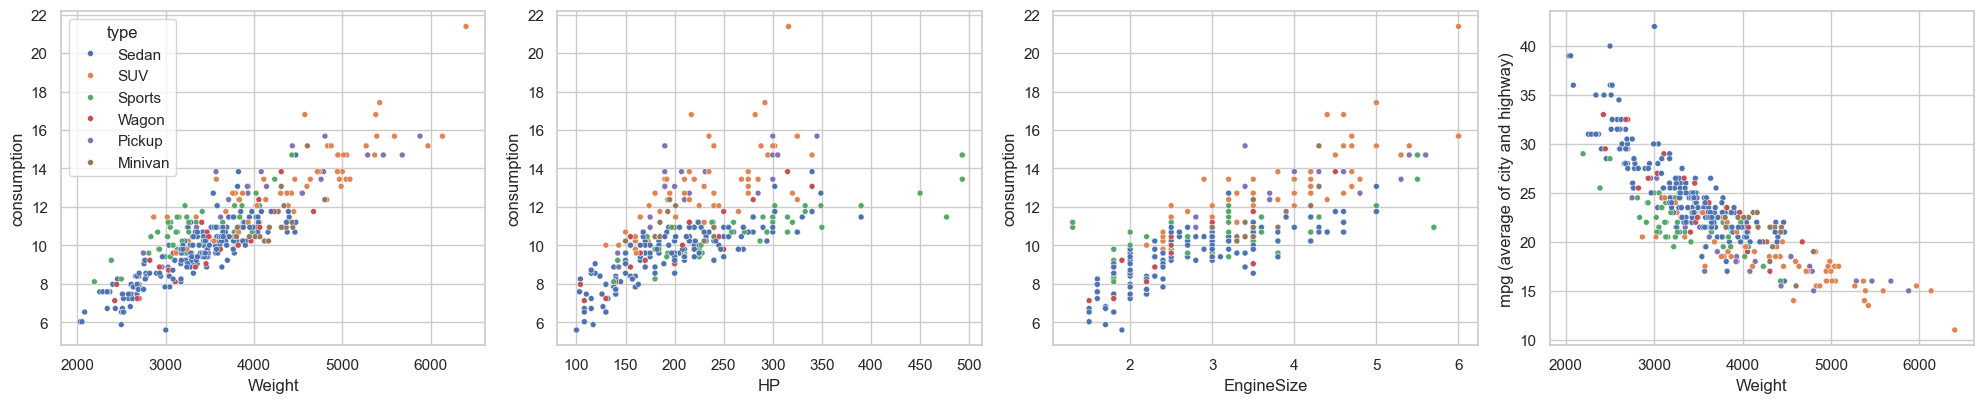

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, x in zip(axes[:3], ['Weight', 'HP', 'EngineSize']):
    sns.scatterplot(data=d04, x=x, y='consumption', hue='type', s=18, ax=ax, legend=(x == 'Weight'))
d04['mpg_avg'] = (d04['CityMPG'] + d04['HwyMPG']) / 2
sns.scatterplot(data=d04, x='Weight', y='mpg_avg', hue='type', s=18, ax=axes[3], legend=False)
axes[3].set_ylabel('mpg (average of city and highway)')
plt.tight_layout()
plt.show()

- Consumption grows roughly **linearly** with weight; mpg falls along a **curve** (mpg $\propto$ 1/consumption). For a linear model: L/100 km.
- SUVs and pickups lie above the sedans at the same weight; more spread at high weights.
- `HP` and `EngineSize` are strongly related to `Weight` (heavy cars have big engines): expect correlated estimates.

**Step 3.** Model and residuals before any test.

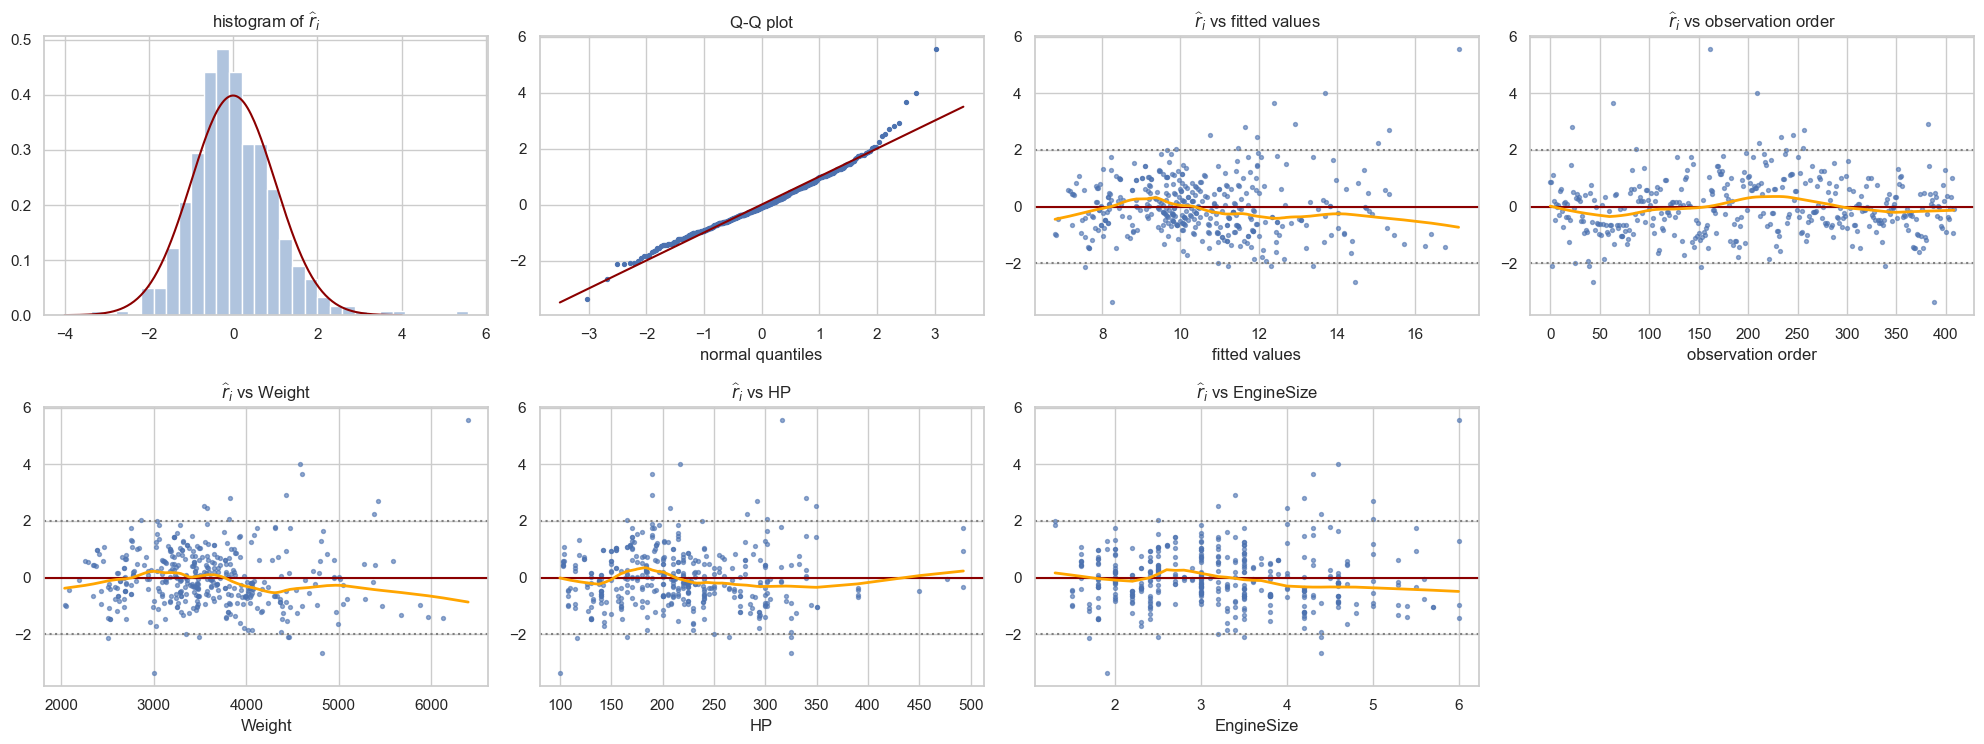

largest |r_i|:


,Name,type,drive,consumption,r
161,Hummer H2,SUV,AWD,21.3832,5.5766
209,Land Rover Discovery SE,SUV,AWD,16.8011,4.0054
63,Chevrolet Astro,Minivan,AWD,15.1752,3.6638
388,Volkswagen Jetta GLS TDI 4dr,Sedan,FWD,5.6004,-3.3823
382,Toyota Tundra Access Cab V6 SR5,Pickup,AWD,15.1752,2.9191


sd of r_i by type: {'Minivan': 1.18, 'Pickup': 1.33, 'SUV': 1.49, 'Sedan': 0.82, 'Sports': 0.93, 'Wagon': 0.92}


In [30]:
form04 = 'consumption ~ Weight + HP + EngineSize + C(type, Treatment("Sedan")) + C(drive, Treatment("FWD"))'
fit04 = smf.ols(form04, data=d04).fit()          # R: lm(consumption ~ Weight + HP + EngineSize + type + drive)
residual_plots(fit04, d04, ['Weight', 'HP', 'EngineSize'])
d04['r'] = fit04.get_influence().resid_studentized_internal
print('largest |r_i|:'); display(d04.loc[d04['r'].abs().nlargest(5).index, ['Name', 'type', 'drive', 'consumption', 'r']])
print('sd of r_i by type:', d04.groupby('type')['r'].std().round(2).to_dict())

- No curvature against fitted values or regressors: the mean structure is fine.
- Largest residuals: Hummer H2 ($\widehat{r}_i \approx 5.6$), Land Rover Discovery, Chevrolet Astro, the Jetta diesel (negative). Heavy off-road vehicles use more than their weight and power predict.
- The spread depends on the type: minivans, pickups and SUVs 1.4–1.8× the sedans. One $s_n$ for all cars: PIs too wide for sedans, too narrow for SUVs (transformations and WLS come in Exercise 09).
- Normality fails only in the tails (Hummer); with $n = 409$ this alone does not spoil the $F$ and $t$ tests (Exercise 06, Section 3.2).
- The different spread by type matters more: the standard errors assume one $\sigma^2$, so the tests below are approximate (Exercise 09).

**Step 4.** ANOVA, $s_n$ in units, the weight coefficient.

In [31]:
display(anova_table(fit04))
print(f'F = {fit04.fvalue:.1f} on {int(fit04.df_model)} and {int(fit04.df_resid)} df;  R^2 = {fit04.rsquared:.4f}, R^2_adj = {fit04.rsquared_adj:.4f}')
s_n04 = np.sqrt(fit04.scale)
print(f's_n = {s_n04:.3f} L/100 km = {100 * s_n04 / d04["consumption"].mean():.1f} % of the mean consumption {d04["consumption"].mean():.2f}')
t_q04 = stats.t.ppf(0.975, fit04.df_resid)
b_w, se_w = fit04.params['Weight'], fit04.bse['Weight']
print(f'Weight per 1000 lb: {1000 * b_w:.3f}, 95 % CI ({1000 * (b_w - t_q04 * se_w):.3f}, {1000 * (b_w + t_q04 * se_w):.3f});'
      f'  conf_int: {(1000 * fit04.conf_int().loc["Weight"]).round(3).tolist()}')
print(f'simple regression consumption ~ Weight: {1000 * smf.ols("consumption ~ Weight", data=d04).fit().params["Weight"]:.3f} per 1000 lb')

,df,SS,MS,F,p-value
Regression,10,1535.5788,153.5579,246.491,1.1227e-163
Residual,398,247.9443,0.6230,NaN,NaN
Total,408,1783.5231,NaN,NaN,NaN


F = 246.5 on 10 and 398 df;  R^2 = 0.8610, R^2_adj = 0.8575
s_n = 0.789 L/100 km = 7.5 % of the mean consumption 10.50
Weight per 1000 lb: 1.421, 95 % CI (1.161, 1.681);  conf_int: [1.161, 1.681]
simple regression consumption ~ Weight: 2.527 per 1000 lb


- $F \approx 246$ on 10 and 398 df: the model explains the consumption ($R^2 = 0.86$; $R^2_{adj}$ almost the same, $n \gg m$).
- $s_n \approx 0.79$ L/100 km, about 7.5 % of the mean consumption: the typical deviation of a car from the model.
- 1000 lb more: $+1.42$ L/100 km (95 % CI 1.16 to 1.68) **at the same power, engine, type and drive**. The simple regression gives $+2.5$: there the weight also carries the bigger engines of heavy cars.

**Step 5.** (a) The type as a whole, (b) AWD vs. RWD.

In [32]:
fit04_red = smf.ols('consumption ~ Weight + HP + EngineSize + C(drive, Treatment("FWD"))', data=d04).fit()
display(anova_lm(fit04_red, fit04))                                   # R: anova(mod_reduced, mod)
type_names = [nm for nm in fit04.params.index if nm.startswith('C(type')]
print(fit04.f_test(', '.join(f'{nm} = 0' for nm in type_names)))
print('individual p-values:', fit04.pvalues[type_names].round(4).to_dict())

# (b) Lemma 3.2 by hand
X04 = fit04.model.exog
cols04 = list(fit04.params.index)
XtX_inv04 = np.linalg.inv(X04.T @ X04)
C_awd = np.zeros((1, len(cols04)))                                   # not C: C() is used in the formulas
C_awd[0, cols04.index('C(drive, Treatment("FWD"))[T.AWD]')] = 1
C_awd[0, cols04.index('C(drive, Treatment("FWD"))[T.RWD]')] = -1
d_awd = C_awd @ fit04.params.to_numpy()
dSSE_awd = float(d_awd @ np.linalg.inv(C_awd @ XtX_inv04 @ C_awd.T) @ d_awd)
F_awd = dSSE_awd / fit04.scale
print(f'beta_AWD - beta_RWD = {d_awd[0]:.3f};  Delta SSE = {dSSE_awd:.3f};  F = {F_awd:.3f}, p = {stats.f.sf(F_awd, 1, fit04.df_resid):.4f}')
print(fit04.f_test('C(drive, Treatment("FWD"))[T.AWD] = C(drive, Treatment("FWD"))[T.RWD]'))
fit04_rwd = smf.ols(form04.replace('Treatment("FWD")', 'Treatment("RWD")'), data=d04).fit()
nm_awd = 'C(drive, Treatment("RWD"))[T.AWD]'
print(f'reference RWD: AWD coefficient {fit04_rwd.params[nm_awd]:.3f}, t^2 = {fit04_rwd.tvalues[nm_awd] ** 2:.3f}, p = {fit04_rwd.pvalues[nm_awd]:.4f}')

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,403.0,327.6171,0.0,NaN,NaN,NaN
1,398.0,247.9443,5.0,79.6728,25.5781,2.1690e-22


<F test: F=25.57814459835788, p=2.1689927707462505e-22, df_denom=398, df_num=5>
individual p-values: {'C(type, Treatment("Sedan"))[T.Minivan]': 0.2338, 'C(type, Treatment("Sedan"))[T.Pickup]': 0.0, 'C(type, Treatment("Sedan"))[T.SUV]': 0.0, 'C(type, Treatment("Sedan"))[T.Sports]': 0.0, 'C(type, Treatment("Sedan"))[T.Wagon]': 0.3899}
beta_AWD - beta_RWD = 0.245;  Delta SSE = 2.159;  F = 3.466, p = 0.0634
<F test: F=3.4660253697754495, p=0.06337854716984806, df_denom=398, df_num=1>
reference RWD: AWD coefficient 0.245, t^2 = 3.466, p = 0.0634


- (a) $\mathbf{C} = (\mathbf{0}, \mathbf{I}_5, \mathbf{0})$ on the five type dummies, $r = 5$: $F \approx 26$, $p \approx 10^{-22}$. The type matters.
  - Individually, minivans and wagons do not differ from sedans; pickups, SUVs and sports cars do. The joint test asks "any difference" and does not depend on the reference level.
- (b) $\mathbf{C} = (0, \dots, 1, -1, \dots, 0)$, $r = 1$: difference $\approx 0.25$ L/100 km, $F \approx 3.5$, $p \approx 0.06$: no clear evidence.
  - $F = t^2$ of the AWD coefficient with `RWD` as the reference.
  - Weight is in the model, so "AWD cars are heavier" is no explanation; AWD mixes permanent all-wheel drive of cars with part-time 4WD of trucks.

**Step 6.** Prediction for a typical front-wheel drive sedan.

In [33]:
fwd_sedans = d04[(d04['type'] == 'Sedan') & (d04['drive'] == 'FWD')]
x0_df = fwd_sedans[['Weight', 'HP', 'EngineSize']].median().to_frame().T.assign(type='Sedan', drive='FWD')
print('x0 =', x0_df.iloc[0].to_dict())
x0_04 = dmatrix(fit04.model.data.design_info, x0_df, return_type='dataframe').to_numpy().ravel()
h0_04 = x0_04 @ XtX_inv04 @ x0_04
y0_04 = x0_04 @ fit04.params.to_numpy()
print(f'y_hat_0 = {y0_04:.3f};  h0 = {h0_04:.4f} (mean leverage {X04.shape[1] / X04.shape[0]:.4f})')
print(f'95 % CI ({y0_04 - t_q04 * s_n04 * np.sqrt(h0_04):.3f}, {y0_04 + t_q04 * s_n04 * np.sqrt(h0_04):.3f}),'
      f'  95 % PI ({y0_04 - t_q04 * s_n04 * np.sqrt(1 + h0_04):.3f}, {y0_04 + t_q04 * s_n04 * np.sqrt(1 + h0_04):.3f})')
display(fit04.get_prediction(x0_df).summary_frame())
near04 = fwd_sedans[fwd_sedans['Weight'].between(3000, 3400) & fwd_sedans['HP'].between(150, 190) & fwd_sedans['EngineSize'].between(2.0, 2.8)]
print(f'{len(near04)} real FWD sedans nearby: mean {near04["consumption"].mean():.2f}, sd {near04["consumption"].std():.2f}')
near04[['Name', 'Weight', 'HP', 'EngineSize', 'consumption']].head(6)

x0 = {'Weight': 3182.0, 'HP': 170.0, 'EngineSize': 2.4, 'type': 'Sedan', 'drive': 'FWD'}


AttributeError: 'PandasData' object has no attribute 'design_info'

- $\mathbf{x}_0$ = median FWD sedan (about 3180 lb, 170 hp, 2.4 L): $\widehat{y}_0 \approx 9.0$ L/100 km, CI about $\pm 0.13$, PI about 7.4 to 10.5.
- $h_0$ far below the mean leverage: a typical car, a precise mean.
- The real neighbours average slightly more, well within the PI; their sd 0.79 also includes their differences in $\mathbf{x}$.
- The PI uses one $s_n$ for all types; for sedans it is somewhat too wide (Step 3).
- $\mathbf{x}_0$ built by `dmatrix(design_info, new)`: the dummies land in the right columns.

**Step 7.** Extrapolation and a second model.

In [34]:
new7 = pd.DataFrame({'Weight': [2500], 'HP': [450], 'EngineSize': [6.0], 'type': ['Sports'], 'drive': ['RWD']})
display(d04[['Weight', 'HP', 'EngineSize']].agg(['min', 'max']))
x7 = dmatrix(fit04.model.data.design_info, new7, return_type='dataframe').to_numpy().ravel()
h04 = np.einsum('ij,jk,ik->i', X04, XtX_inv04, X04)
h7 = x7 @ XtX_inv04 @ x7
print(f'h0 = {h7:.4f};  max h_ii = {h04.max():.4f} ({d04.loc[h04.argmax(), "Name"]});  ratio {h7 / h04.max():.2f}')
print('cars with 450 hp or more:'); display(d04[d04['HP'] >= 450][['Name', 'Weight', 'HP', 'EngineSize', 'consumption']])

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=d04, x='Weight', y='HP', hue='type', s=18, ax=ax)
ax.plot(new7['Weight'], new7['HP'], 'r*', ms=18, label='planned car')
ax.plot(x0_df['Weight'], x0_df['HP'], 'k*', ms=14, label='typical sedan (Step 6)')
ax.legend()
plt.show()

fit04_log = smf.ols('np.log(consumption) ~ np.log(Weight) + np.log(HP) + np.log(EngineSize) + C(type, Treatment("Sedan")) + C(drive, Treatment("FWD"))', data=d04).fit()
residual_plots(fit04_log, d04, ['Weight', 'HP', 'EngineSize'])
rows = {}
for label, x_new in [('typical sedan', x0_df), ('planned sports car', new7)]:
    lin = fit04.get_prediction(x_new).summary_frame()
    lg = np.exp(fit04_log.get_prediction(x_new).summary_frame())           # back to L/100 km (median)
    rows[label] = {'linear': lin['mean'].iloc[0], 'linear CI': f'{lin["mean_ci_lower"].iloc[0]:.2f}-{lin["mean_ci_upper"].iloc[0]:.2f}',
                   'log-log': lg['mean'].iloc[0], 'log-log CI': f'{lg["mean_ci_lower"].iloc[0]:.2f}-{lg["mean_ci_upper"].iloc[0]:.2f}'}
display(pd.DataFrame(rows).T)
print(f'log-log: elasticity of Weight {fit04_log.params["np.log(Weight)"]:.3f} (CI {fit04_log.conf_int().loc["np.log(Weight)"].round(3).tolist()})')
rmse_lin = np.sqrt(np.mean((d04['consumption'] - fit04.fittedvalues) ** 2))
rmse_log = np.sqrt(np.mean((d04['consumption'] - np.exp(fit04_log.fittedvalues)) ** 2))
print(f'RMSE in L/100 km: linear {rmse_lin:.3f}, log-log {rmse_log:.3f}')
r_log = fit04_log.get_influence().resid_studentized_internal
print(f'log-log, largest |r_i|: {d04.loc[np.argmax(np.abs(r_log)), "Name"]}, r_i = {r_log[np.argmax(np.abs(r_log))]:.2f}')

,Weight,HP,EngineSize
min,2035.0,100,1.3
max,6400.0,493,6.0


AttributeError: 'PandasData' object has no attribute 'design_info'

- Each value is inside its own range (weight 2035–6400 lb, power 100–493 hp, engine 1.3–6.0 L).
- But $h_0 \approx 0.18$, about 1.8× the largest leverage (Porsche 911 GT2, itself the extreme car). Cars with 450 hp or more weigh 3100–4500 lb; nothing like 2500 lb with a 6.0 L engine exists in the data.
- The plot shows it at once: the planned car lies far above the cloud of `HP` against `Weight`.
- Two models with a similar fit (RMSE about 0.78 L/100 km for both) and sensible residuals (log-log: +1 % weight $\Rightarrow$ about +0.45 % consumption; one outlier, the Jetta diesel, $\widehat{r}_i \approx -5$):
  - typical sedan: they agree to about 0.01 L/100 km;
  - planned car: they differ by about 0.5 L/100 km, almost the half-width of either CI.
- **Away from the data the answer depends on the model, and neither CI knows it.** Report "about 11 L/100 km, like other big sports cars", not two decimals.

Sections 3–5 continue with the linear model `fit04`.

## 3. Three scales of residuals (pp. 108–109)
$\mathsf{Var}\,\widehat{e}_i = \sigma^2(1 - h_{ii})$: residuals of points with a large $h_{ii}$ are smaller **by construction**. Three ways to put them on one scale:

| residual | formula | statsmodels / R | use |
|---|---|---|---|
| scaled by $s_n$ | $\widehat{e}_i / s_n$ | `resid / np.sqrt(scale)` | quick look, only if all $h_{ii}$ are small |
| **internally studentized** (interně studentizované) | $\widehat{r}_i = \dfrac{\widehat{e}_i}{s_n\sqrt{1 - h_{ii}}}$ | `resid_studentized_internal` / `rstandard` | residual plots, Q-Q plot |
| **externally studentized** (externě studentizované) | $\widehat{t}_i = \dfrac{\widehat{e}_i}{\widehat{\sigma}_{(-i)}\sqrt{1 - h_{ii}}}$ | `resid_studentized_external` / `rstudent` | is the $i$-th observation an outlier? |

- $\widehat{\sigma}^2_{(-i)} = \mathrm{SSE}_{(-i)}/(n-m-2)$ from the model **without** the $i$-th observation: an outlier cannot inflate its own denominator.
- Names are a mess: R calls $\widehat{r}_i$ "standardized" (the slides, p. 108, also say "sometimes standardized"), the slides (p. 60) call "standardized" the residual divided by the true $\sigma$, some books call $\widehat{e}_i/s_n$ "standardized". Check the formula, not the name.
- No refit is needed:
  - $\mathrm{SSE}_{(-i)} = \mathrm{SSE} - \widehat{e}_i^2/(1 - h_{ii})$,
  - $\widehat{t}_i = \widehat{r}_i\sqrt{\dfrac{n-m-2}{n-m-1-\widehat{r}_i^2}}$, an increasing function of $\widehat{r}_i$: the same ordering.
- $\widehat{t}_i \sim t(n-m-2)$ exactly under the model with normal errors; the test of an outlier with the Bonferroni correction comes with the influence measures in Exercise 08.

On the 2004 cars: by hand, with the formula, and by refitting without the Hummer.

In [35]:
X = fit04.model.exog
y = fit04.model.endog
n, p = X.shape                                    # p = m + 1
e_hat = fit04.resid.to_numpy()
s_n = np.sqrt(fit04.scale)
h = np.sum(np.linalg.qr(X)[0] ** 2, axis=1)       # h_ii = squared row norms of Q (Exercise 04)

r_i = e_hat / (s_n * np.sqrt(1 - h))
SSE_del = np.sum(e_hat ** 2) - e_hat ** 2 / (1 - h)                 # SSE_(-i) without refitting
t_i = e_hat / (np.sqrt(SSE_del / (n - p - 1)) * np.sqrt(1 - h))
t_formula = r_i * np.sqrt((n - p - 1) / (n - p - r_i ** 2))
infl04 = fit04.get_influence()
print(f'max |r_i - statsmodels| = {np.abs(r_i - infl04.resid_studentized_internal).max():.1e}')
print(f'max |t_i - statsmodels| = {np.abs(t_i - infl04.resid_studentized_external).max():.1e},'
      f'  max |t_i - formula from r_i| = {np.abs(t_i - t_formula).max():.1e}')

# the Hummer: refit without it
k = int(np.argmax(np.abs(r_i)))
fit_wo = sm.OLS(np.delete(y, k), np.delete(X, k, axis=0)).fit()
t_refit = (y[k] - X[k] @ fit_wo.params) / np.sqrt(fit_wo.scale * (1 + X[k] @ np.linalg.inv(fit_wo.model.exog.T @ fit_wo.model.exog) @ X[k]))
print(f'{d04.loc[k, "Name"]}: sigma_(-i) from the formula {np.sqrt(SSE_del[k] / (n - p - 1)):.4f}, from the refit {np.sqrt(fit_wo.scale):.4f};'
      f'  t_i = {t_i[k]:.3f}, from the refit (prediction error / its SE) = {t_refit:.3f}')

scales04 = d04[['Name', 'type']].assign(h_ii=h, e_over_s_n=e_hat / s_n, r_i=r_i, t_i=t_i)
scales04.loc[scales04['t_i'].abs().nlargest(5).index]

max |r_i - statsmodels| = 8.9e-14
max |t_i - statsmodels| = 1.1e-13,  max |t_i - formula from r_i| = 8.9e-16
Hummer H2: sigma_(-i) from the formula 0.7588, from the refit 0.7588;  t_i = 5.801, from the refit (prediction error / its SE) = 5.801


,Name,type,h_ii,e_over_s_n,r_i,t_i
161,Hummer H2,SUV,0.0583,5.4116,5.5766,5.8008
209,Land Rover Discovery SE,SUV,0.0279,3.9492,4.0054,4.0835
63,Chevrolet Astro,Minivan,0.0729,3.5276,3.6638,3.7225
388,Volkswagen Jetta GLS TDI 4dr,Sedan,0.0139,-3.3587,-3.3823,-3.4277
382,Toyota Tundra Access Cab V6 SR5,Pickup,0.0553,2.8372,2.9191,2.9471


- All three routes give the same $\widehat{t}_i$, also the refit without the Hummer: $\widehat{t}_i$ is the prediction error of the $i$-th car by the model that did not see it, divided by its standard error (Exercise 06, Section 7).
- Here all $h_{ii} < 0.1$ and $n = 409$: the three scales differ by a few per cent only (Remark 4.1). Only the Hummer moves visibly: $\widehat{r}_i \approx 5.6$, $\widehat{t}_i \approx 5.8$, because without it $\widehat{\sigma}$ drops.

**When the scales differ: small $n$, a large $h_{ii}$.** Example 3.4 of the slides (birth weight, $n = 24$) and the boy born in week 35 (Exercise 06, Section 4.3):

In [36]:
fit_b = smf.ols('Weight ~ Age + Sex', data=birth).fit()          # R: lm(Weight ~ Age + Sex)
infl_b = fit_b.get_influence()
scales_b = birth.assign(h_ii=infl_b.hat_matrix_diag, e_over_s_n=fit_b.resid / np.sqrt(fit_b.scale),
                        r_i=infl_b.resid_studentized_internal, t_i=infl_b.resid_studentized_external)
scales_b.loc[scales_b['t_i'].abs().nlargest(4).index]

,Weight,Age,Sex,h_ii,e_over_s_n,r_i,t_i
3,2925,35,boy,0.2316,1.7163,1.9580,2.1134
0,2968,40,boy,0.1204,-1.4538,-1.5501,-1.6075
12,3317,40,girl,0.1042,1.4372,1.5185,1.5706
7,3473,40,boy,0.1204,1.3974,1.4900,1.5377


- The boy of week 35 has the largest $h_{ii} \approx 0.23$ (the youngest newborn). His residual is the largest on every scale, but it is below 2 scaled by $s_n$ (1.7) and above 2 as $\widehat{t}_i$ (2.1); $\widehat{r}_i \approx 1.96$.
- A point with a large leverage pulls the fit towards itself, so its raw residual understates how badly it fits; $\widehat{r}_i$ corrects this, $\widehat{t}_i$ also removes it from $\widehat{\sigma}$.
- For small $n$ or large $h_{ii}$ use $\widehat{r}_i$ or $\widehat{t}_i$, never $\widehat{e}_i/s_n$ (Remark 4.1).

## 4. Leverage $h_{ii}$ (p. 110)
Properties from the slides, checked numerically:
- $\frac{1}{n} \le h_{ii} \le 1$ (in a model with an intercept),
- $\sum_j h_{ij} = 1$ for every $i$ (the intercept column: $\mathbf{H}\mathbf{1} = \mathbf{1}$),
- $\sum_i h_{ii} = \mathrm{tr}\,\mathbf{H} = m + 1$, so the mean leverage is $(m+1)/n$,
- $\widehat{y}_i = h_{ii}y_i + \sum_{j \ne i}h_{ij}y_j$: if $h_{ii} \approx 1$, the fit is forced through the point.
- Heuristic rule: **large leverage** if $h_{ii} > 3(m+1)/n$.

In [37]:
H04 = X @ XtX_inv04 @ X.T                     # n x n is fine for n = 409; not for large n (Exercise 04)
print(f'1/n = {1 / n:.4f} <= min h_ii = {h.min():.4f};  max h_ii = {h.max():.4f} <= 1')
print(f'row sums of H: min {H04.sum(axis=1).min():.6f}, max {H04.sum(axis=1).max():.6f}')
print(f'sum h_ii = {h.sum():.4f} = m + 1 = {p};  mean (m+1)/n = {p / n:.4f};  threshold 3(m+1)/n = {3 * p / n:.4f}')
lev04 = scales04.assign(Weight=d04['Weight'], HP=d04['HP'], EngineSize=d04['EngineSize'], drive=d04['drive'])
lev04.sort_values('h_ii', ascending=False).head(6)

1/n = 0.0024 <= min h_ii = 0.0059;  max h_ii = 0.0969 <= 1
row sums of H: min 1.000000, max 1.000000
sum h_ii = 11.0000 = m + 1 = 11;  mean (m+1)/n = 0.0269;  threshold 3(m+1)/n = 0.0807


,Name,type,h_ii,e_over_s_n,r_i,t_i,Weight,HP,EngineSize,drive
316,Porsche 911 GT2 2dr,Sports,0.0969,-0.0405,-0.0426,-0.0425,3131.0,477,3.6,RWD
58,Cadillac Escalade EXT,Pickup,0.0745,-0.9289,-0.9655,-0.9654,5879.0,345,6.0,AWD
71,Chevrolet Corvette 2dr,Sports,0.0739,-0.9867,-1.0253,-1.0254,3246.0,350,5.7,RWD
72,Chevrolet Corvette convertible 2dr,Sports,0.0737,-0.9903,-1.0290,-1.0290,3248.0,350,5.7,RWD
142,GMC Safari SLE,Minivan,0.0731,1.7003,1.7661,1.7708,4309.0,190,4.3,RWD
63,Chevrolet Astro,Minivan,0.0729,3.5276,3.6638,3.7225,4605.0,190,4.3,AWD


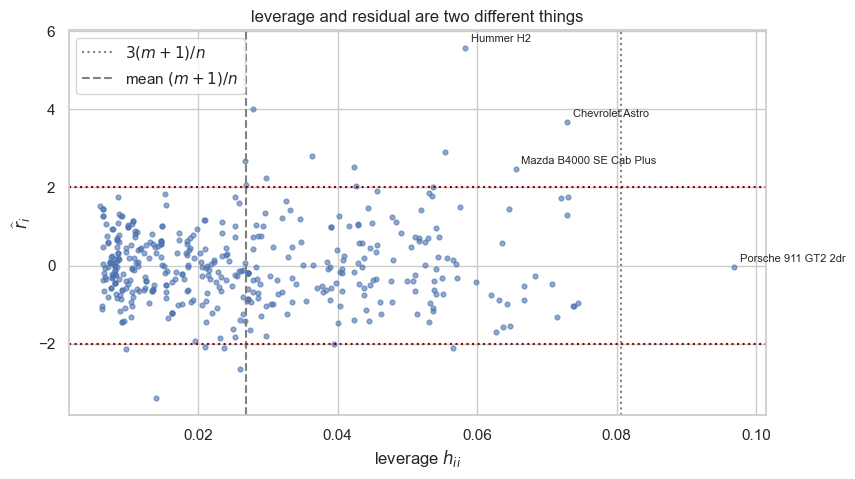

In [38]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(h, r_i, s=12, alpha=0.6)
ax.axvline(3 * p / n, color='gray', ls=':', label='$3(m+1)/n$')
ax.axvline(p / n, color='gray', ls='--', label='mean $(m+1)/n$')
for b in (-2, 2):
    ax.axhline(b, color='darkred', ls=':')
for k_ in dict.fromkeys([int(np.argmax(h)), int(np.argmax(np.abs(r_i)))] + [int(v) for v in np.argsort(-(np.abs(r_i) * h))[:3]]):
    ax.annotate(d04.loc[k_, 'Name'], (h[k_], r_i[k_]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('leverage $h_{ii}$'); ax.set_ylabel('$\\widehat{r}_i$'); ax.legend()
ax.set_title('leverage and residual are two different things')
plt.show()

- Only the **Porsche 911 GT2** exceeds $3(m+1)/n \approx 0.08$: 477 hp at 3131 lb, the most unusual combination of regressors. Its residual is almost zero: it fits.
- The **Hummer** has the largest residual and only a moderate leverage ($h_{ii} \approx 0.06$, below the threshold): an unusual consumption for a not so unusual combination of $\mathbf{x}$.
- The **Chevrolet Astro** has one of the highest leverages (0.073, also below the threshold) and $\widehat{r}_i \approx 3.7$: the kind of car to look at first. Whether such a car changes the fit is the question of the influence measures (DFBETAS, Cook's distance) in Exercise 08.
- $h_{ii}$ is a distance in the space of the regressors; it does not use $y$ (HW04, Task 06: the 200-year-old houses; Exercise 06, Section 7.2: the Buick; Section 2, Step 7 here: the planned sports car).

## 5. Residual plots, partial residual plots, added variable plots (pp. 111–118)

### 5.1 Normality (p. 111)
Histogram and Q-Q plot of $\widehat{r}_i$ are the same as in simple regression and do not depend on the number of regressors. The slides name the tests of normality: Shapiro–Wilk, Lilliefors, Anderson–Darling.

In [39]:
print('Shapiro-Wilk, all cars:            ', stats.shapiro(r_i))
keep = np.abs(r_i) < 4
print(f'Shapiro-Wilk without {np.sum(~keep)} cars |r_i| >= 4:', stats.shapiro(r_i[keep]))

Shapiro-Wilk, all cars:             ShapiroResult(statistic=np.float64(0.9665040897988908), pvalue=np.float64(4.674970624188635e-08))
Shapiro-Wilk without 2 cars |r_i| >= 4: ShapiroResult(statistic=np.float64(0.990746918455195), pvalue=np.float64(0.011796246382343011))


- With $n = 409$ the test notices small departures; most of them come from the tails (Hummer, Land Rover, the diesel). Without the two cars with $|\widehat{r}_i| \ge 4$ the $p$-value grows, but the right tail is still a bit heavy.
- A test does not say how much the departure matters. For $t$ and $F$ with $n = 409$ it matters little (Exercise 06, Section 3.2); for the prediction interval of one car it matters more (the PI assumes normal errors).

### 5.2 Residuals against $x_j$ and $\widehat{y}$ (pp. 111–113)
Remark 4.2: the normal equations give $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$ and $\widehat{\mathbf{y}}^T\widehat{\mathbf{e}} = 0$, so the least squares line through the origin of $\widehat{\mathbf{e}}$ on any column $\mathbf{x}_j$ or on $\widehat{\mathbf{y}}$ has slope 0 (exactly for $\widehat{e}_i$, approximately for $\widehat{r}_i$). A **linear** trend is impossible by construction; what remains visible is curvature and a changing spread (the key to the shapes in Exercise 05, Section 5.4).

X^T e / ||x_j|| : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
y_hat^T e = 2.0e-09


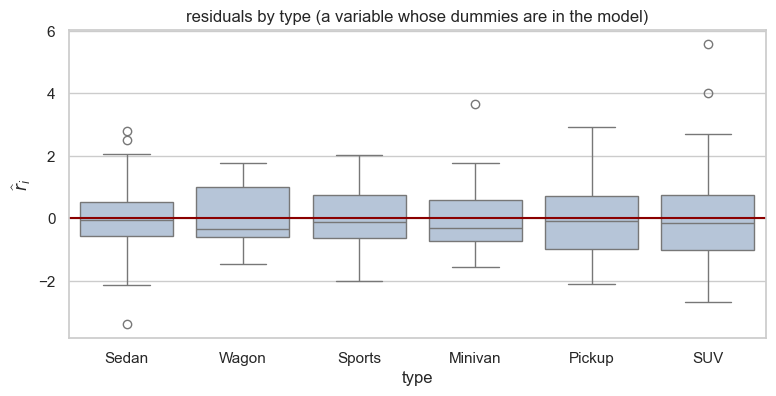

In [40]:
y_hat = fit04.fittedvalues.to_numpy()
print('X^T e / ||x_j|| :', (X.T @ e_hat / np.linalg.norm(X, axis=0)).round(10))
print(f'y_hat^T e = {y_hat @ e_hat:.1e}')

fig, ax = plt.subplots(figsize=(9, 4))
order = d04.groupby('type')['r'].std().sort_values().index
sns.boxplot(x=d04['type'], y=r_i, order=order, ax=ax, color='lightsteelblue')
ax.axhline(0, color='darkred'); ax.set_ylabel('$\\widehat{r}_i$')
ax.set_title('residuals by type (a variable whose dummies are in the model)')
plt.show()

- Within each type the residuals have mean zero (the type dummies are in the model), but not the same spread: sedans about 0.8, SUVs about 1.5 (in units of $s_n$). A funnel by group.
- The tests of constant variance named on the slides (p. 111), Breusch–Pagan and Levene, come with weighted least squares in Exercise 09.

### 5.3 Partial residual plots (pp. 113–116)
In a multiple model $\widehat{\mathbf{e}}$ depends on all regressors; a curve in $\widehat{\mathbf{e}}$ against $\mathbf{x}_j$ does not tell how the effect of $x_j$ looks. **Partial residuals** add the fitted effect of $x_j$ back:

$$\widehat{\mathbf{e}}^{\ast}_j = \widehat{\mathbf{e}} + \widehat{\beta}_j\mathbf{x}_j, \qquad \text{plot } \widehat{\mathbf{e}}^{\ast}_j \text{ against } \mathbf{x}_j.$$

- If the model is right, the points scatter around a line with slope $\widehat{\beta}_j$ (the line through the origin of $\widehat{\mathbf{e}}^{\ast}_j$ on $\mathbf{x}_j$ has slope exactly $\widehat{\beta}_j$, because $\mathbf{x}_j^T\widehat{\mathbf{e}} = 0$).
- statsmodels `sm.graphics.plot_ccpr` (component and component-plus-residual), R `termplot(mod, partial.resid = TRUE)`, `car::crPlots`. `termplot` centres the term, $\widehat{\beta}_j(x_{ij} - \overline{x}_j)$; the shape is the same.

**A promise from Exercise 05, Section 5.4:** `mpg ~ weight + horsepower + model_year` showed a U-shape in the residuals. Which regressor is nonlinear?

weight: slope through the origin of the partial residuals = -0.006448, beta_j = -0.006448
horsepower: slope through the origin of the partial residuals = -0.005000, beta_j = -0.005000
model_year: slope through the origin of the partial residuals = 0.748705, beta_j = 0.748705


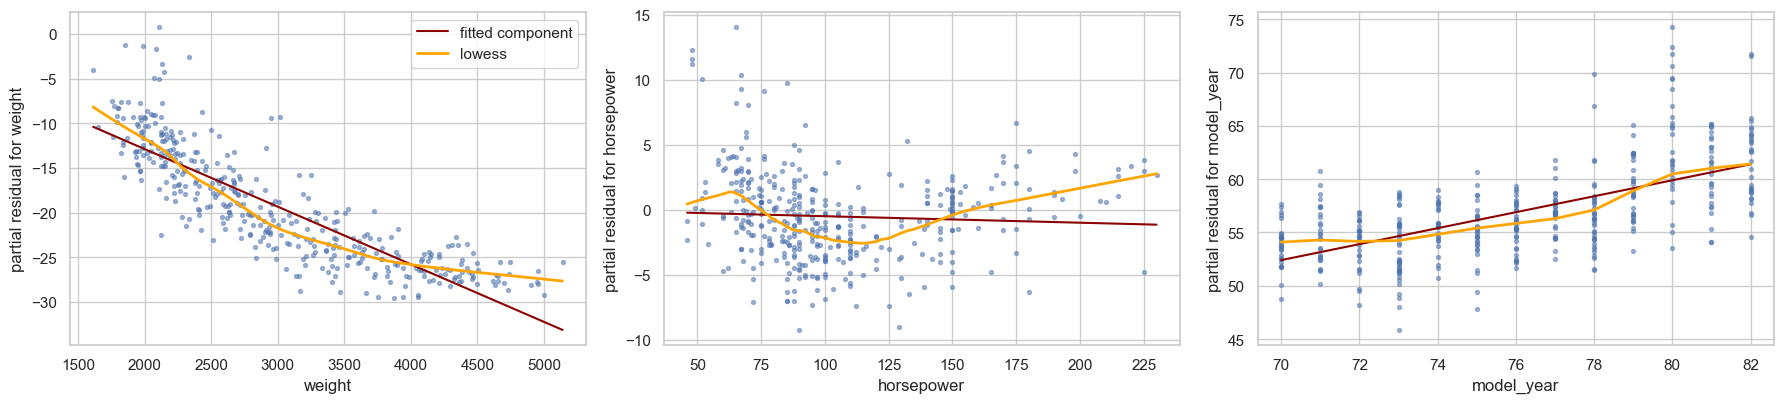

corr(weight, horsepower) = 0.865


In [41]:
fit_mpg = smf.ols('mpg ~ weight + horsepower + model_year', data=cars).fit()     # R: lm(mpg ~ weight + horsepower + model_year)


def partial_residual_plot(fit, data, var, ax, extra=None):
    """e + beta_j x_j against x_j; extra = names of further terms of the same variable (e.g. its square)."""
    x = data[var].to_numpy(dtype=float)
    comp = fit.params[var] * x
    for term, fun in (extra or {}).items():
        comp = comp + fit.params[term] * fun(x)
    pres = fit.resid.to_numpy() + comp
    ax.scatter(x, pres, s=8, alpha=0.5)
    o = np.argsort(x)
    ax.plot(x[o], comp[o], color='darkred', label='fitted component')
    smooth = sm.nonparametric.lowess(pres, x, frac=0.3)
    ax.plot(smooth[:, 0], smooth[:, 1], color='orange', lw=2, label='lowess')
    ax.set_xlabel(var); ax.set_ylabel(f'partial residual for {var}')
    return pres


fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, v in zip(axes, ['weight', 'horsepower', 'model_year']):
    pres = partial_residual_plot(fit_mpg, cars, v, ax)
    x = cars[v].to_numpy(dtype=float)
    print(f'{v}: slope through the origin of the partial residuals = {x @ pres / (x @ x):.6f}, beta_j = {fit_mpg.params[v]:.6f}')
axes[0].legend()
plt.tight_layout()
plt.show()
print(f'corr(weight, horsepower) = {cars["weight"].corr(cars["horsepower"]):.3f}')

- The slope check holds: the partial residuals scatter around the fitted component $\widehat{\beta}_j x_j$.
- **Both** `weight` and `horsepower` show a convex curve; `model_year` looks roughly linear.
- The two are correlated (0.86): the curvature of one partly shows up in the partial residuals of the other. The plot suggests candidates, a refit decides.

,R^2,s_n
linear,0.8083,3.4303
+ weight^2,0.8521,3.0166
+ horsepower^2,0.8431,3.1076
+ both squares,0.8598,2.9412


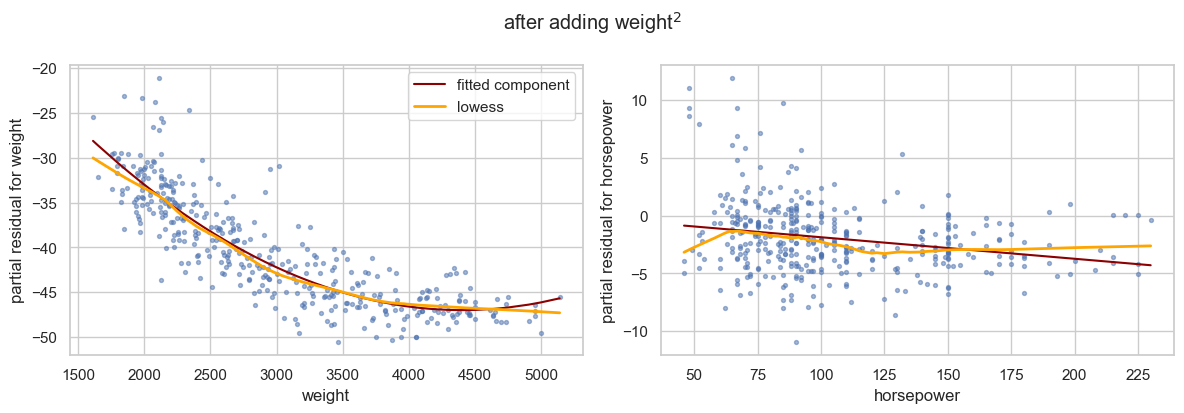

In [42]:
cands = {'linear': 'mpg ~ weight + horsepower + model_year',
         '+ weight^2': 'mpg ~ weight + I(weight**2) + horsepower + model_year',
         '+ horsepower^2': 'mpg ~ weight + horsepower + I(horsepower**2) + model_year',
         '+ both squares': 'mpg ~ weight + I(weight**2) + horsepower + I(horsepower**2) + model_year'}
fits_mpg = {k_: smf.ols(f, data=cars).fit() for k_, f in cands.items()}
display(pd.DataFrame({k_: {'R^2': f.rsquared, 's_n': np.sqrt(f.scale)} for k_, f in fits_mpg.items()}).T)

fit_w2 = fits_mpg['+ weight^2']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
partial_residual_plot(fit_w2, cars, 'weight', axes[0], extra={'I(weight ** 2)': lambda x: x ** 2})
partial_residual_plot(fit_w2, cars, 'horsepower', axes[1])
axes[0].legend(); fig.suptitle('after adding weight$^2$')
plt.tight_layout()
plt.show()
# statsmodels draws the uncentred PRP of one term with sm.graphics.plot_ccpr(fit_w2, 'horsepower')

- `weight`$^2$ alone gives most of the gain ($R^2$ 0.81 → 0.85, $s_n$ 3.4 → 3.0 mpg); `horsepower`$^2$ alone less; both squares add little more.
- After adding `weight`$^2$ the partial residuals for `horsepower` are much straighter: most of its curvature was borrowed from `weight`.
- The square turns up again above about 4700 lb, where there are few cars: a local repair, not a law to extrapolate.
- The convex effect of weight is the curve of mpg $\propto$ 1/consumption from Section 2, Step 2: the transformation of the response (Exercise 09) is the more natural alternative.

**Example 4.2 of the slides: birth weight.** `termplot(mod, partial.resid = TRUE)` for `Weight ~ Age + Sex` (p. 116); statsmodels draws the same with `plot_ccpr` (uncentred).

Age: partial residuals from -474 to 431
girl: partial residuals from -248 to 386


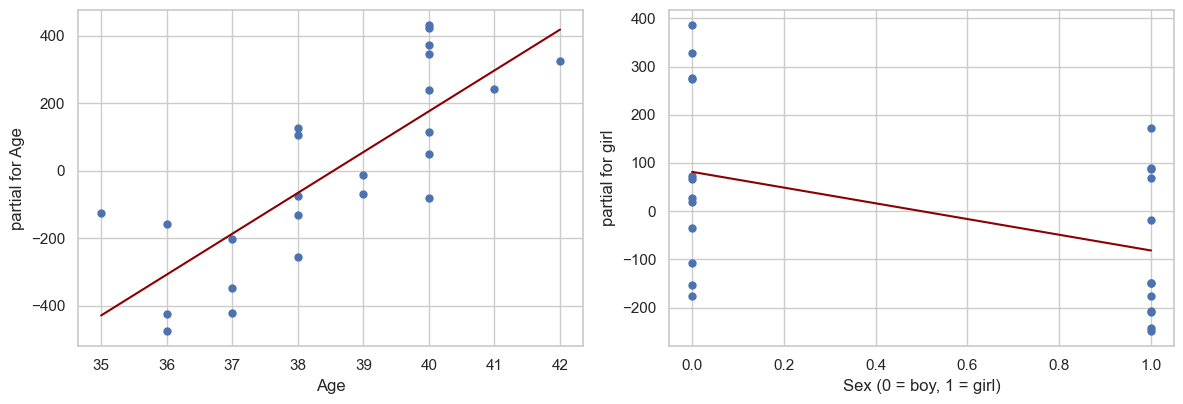

In [43]:
birth['girl'] = (birth['Sex'] == 'girl').astype(float)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (v, term) in zip(axes, [('Age', 'Age'), ('girl', 'Sex[T.girl]')]):
    x = birth[v].to_numpy()
    comp = fit_b.params[term] * (x - x.mean())                      # centred like termplot
    pres = fit_b.resid.to_numpy() + comp
    ax.scatter(x, pres, s=25)
    o = np.argsort(x)
    ax.plot(x[o], comp[o], color='darkred')
    ax.set_xlabel(v if v == 'Age' else 'Sex (0 = boy, 1 = girl)'); ax.set_ylabel(f'partial for {v}')
    print(f'{v}: partial residuals from {pres.min():.0f} to {pres.max():.0f}')
plt.tight_layout()
plt.show()

- The ranges match the figure on p. 116: about $-470$ to $430$ g for `Age`, two groups at $\pm 82$ g for `Sex`.
- `Age` looks linear; the boy of week 35 lies well above the line (Section 3).
- For a factor the PRP is a comparison of two clouds: the spreads of boys and girls are similar.

### 5.4 Added variable plots (pp. 117–118)
The slides (p. 117) note that PRPs are sometimes criticized for overstating the effect of $x_j$. The **added variable plot** (partial regression plot) removes the other regressors from **both** axes:

$$\widehat{\mathbf{e}}_{(-j)} = (\mathbf{I} - \mathbf{H}_{(-j)})\mathbf{y} \quad \text{against} \quad \mathbf{x}_{j,res} = (\mathbf{I} - \mathbf{H}_{(-j)})\mathbf{x}_j,$$

where $\mathbf{H}_{(-j)}$ is the hat matrix of $\mathbf{X}$ without column $j$. This is the Frisch–Waugh–Lovell construction of Exercise 04, Section 6:
- the slope through the origin is exactly $\widehat{\beta}_j$ (formula 4.1),
- the residuals around this line are exactly the residuals $\widehat{\mathbf{e}}$ of the full model,
- the horizontal spread is the part of $x_j$ not explained by the other regressors: $\mathrm{sd}(\mathbf{x}_{j,res}) = \mathrm{sd}(\mathbf{x}_j)\sqrt{1 - R_j^2}$.

statsmodels `sm.graphics.plot_partregress_grid`, R `car::avPlots`. On the 2004 cars, `Weight` by hand:

In [44]:
def added_variable(fit, var):
    X_ = fit.model.exog
    j = fit.model.exog_names.index(var)
    X_o = np.delete(X_, j, axis=1)
    e_y = fit.model.endog - X_o @ np.linalg.lstsq(X_o, fit.model.endog, rcond=None)[0]
    x_r = X_[:, j] - X_o @ np.linalg.lstsq(X_o, X_[:, j], rcond=None)[0]
    return e_y, x_r


e_y, x_r = added_variable(fit04, 'Weight')
slope = x_r @ e_y / (x_r @ x_r)
print(f'AV slope = {slope:.6f},  beta_Weight = {fit04.params["Weight"]:.6f}')
print(f'max |residuals of the AV line - residuals of the full model| = {np.abs(e_y - slope * x_r - e_hat).max():.1e}')
R2_w = 1 - np.sum(x_r ** 2) / np.sum((d04['Weight'] - d04['Weight'].mean()) ** 2)
print(f'sd(Weight) = {d04["Weight"].std(ddof=0):.0f} lb,  sd(Weight | others) = {x_r.std():.0f} lb,  R_j^2 = {R2_w:.3f}')

AV slope = 0.001421,  beta_Weight = 0.001421
max |residuals of the AV line - residuals of the full model| = 6.1e-13
sd(Weight) = 725 lb,  sd(Weight | others) = 295 lb,  R_j^2 = 0.834


Weight: sd(x) = 725,  sd(x | others) = 295
HP: sd(x) = 68.9,  sd(x | others) = 35
EngineSize: sd(x) = 1.04,  sd(x | others) = 0.465


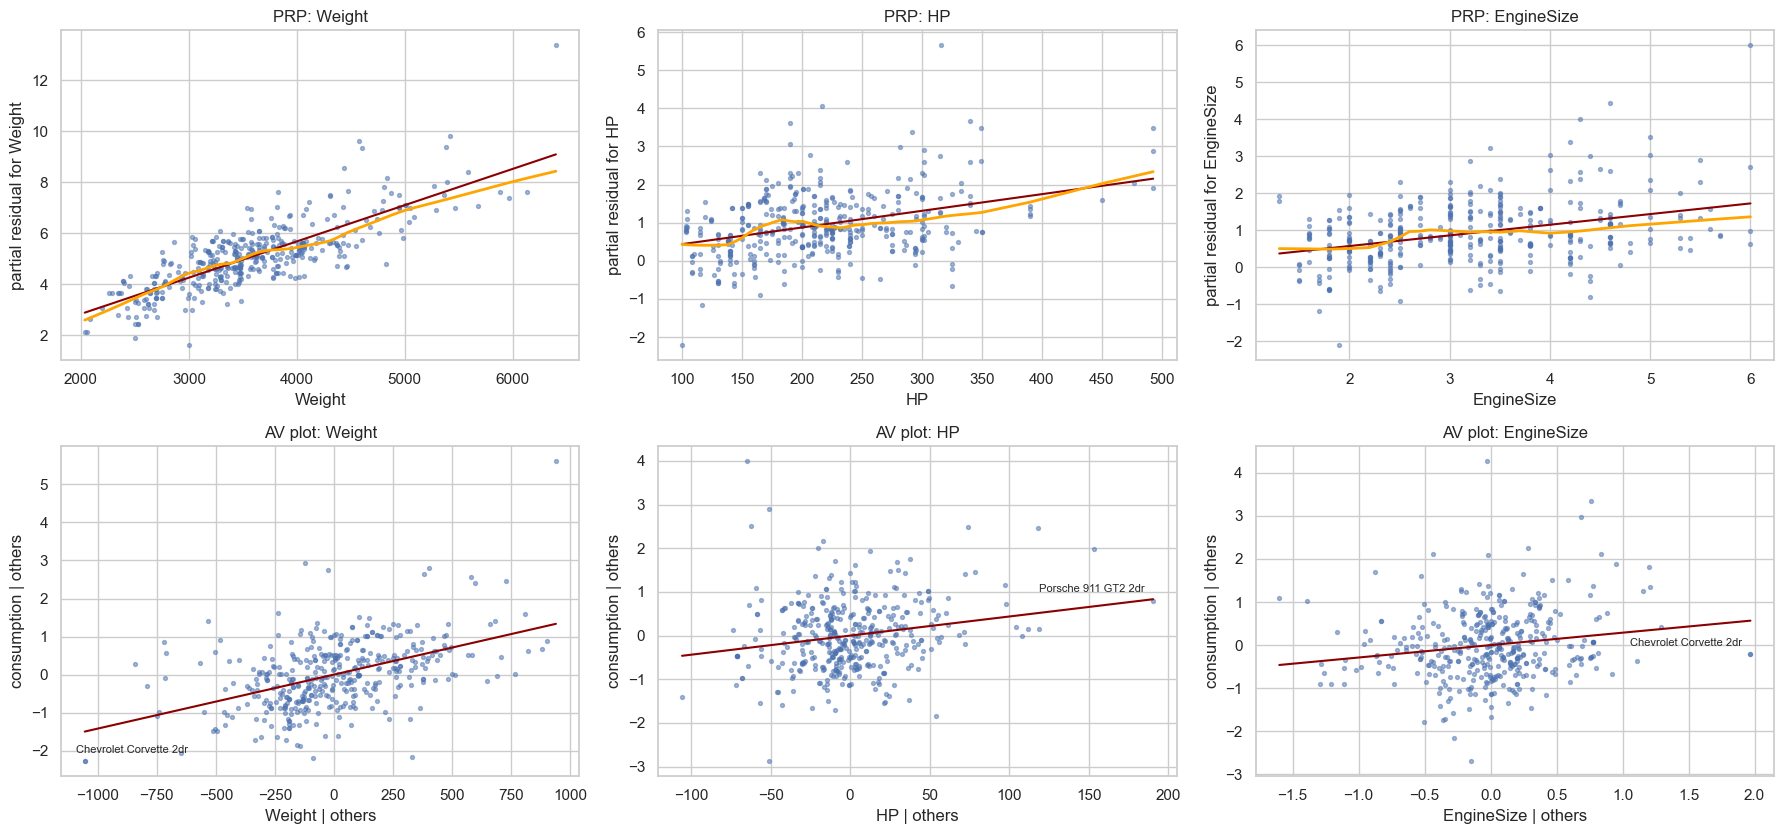

In [45]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
for col, v in enumerate(['Weight', 'HP', 'EngineSize']):
    partial_residual_plot(fit04, d04, v, axes[0, col])
    axes[0, col].set_title(f'PRP: {v}')
    e_y, x_r = added_variable(fit04, v)
    axes[1, col].scatter(x_r, e_y, s=8, alpha=0.5)
    g = np.linspace(x_r.min(), x_r.max(), 2)
    axes[1, col].plot(g, fit04.params[v] * g, color='darkred')
    axes[1, col].set_xlabel(f'{v} | others'); axes[1, col].set_ylabel('consumption | others')
    axes[1, col].set_title(f'AV plot: {v}')
    k_ = int(np.argmax(np.abs(x_r)))
    axes[1, col].annotate(d04.loc[k_, 'Name'], (x_r[k_], e_y[k_]), fontsize=8, xytext=(-6, 6), textcoords='offset points',
                          ha='right' if x_r[k_] > 0 else 'left')
    print(f'{v}: sd(x) = {d04[v].std(ddof=0):.3g},  sd(x | others) = {x_r.std():.3g}')
plt.tight_layout()
plt.show()
# the same AV plots from statsmodels:
# sm.graphics.plot_partregress_grid(fit04, exog_idx=['Weight', 'HP', 'EngineSize'])

- The three regressors are strongly correlated ($R_j^2$ about 0.74–0.83): in the AV plots the horizontal spread shrinks to 40–50 % of the PRP. That is the information from which $\widehat{\beta}_j$ is estimated: by FWL, $\mathsf{Var}\,\widehat{\beta}_j = \sigma^2/\|\mathbf{x}_{j,res}\|^2$, i.e. $1/(1 - R_j^2)$ times what the same $\sigma^2$ would give without the other regressors (VIF, Exercise 06, Section 4.3; collinearity in Exercise 11).
- The PRP shows the whole range of $x_j$, so the effect looks better determined than it is; one reading of the criticism on p. 117.
- The AV plot shows which cars carry $\widehat{\beta}_j$: the cars at the ends of the horizontal axis, unusual in $x_j$ **given** the others (e.g. a light car with a big engine). Their influence on $\widehat{\beta}_j$ is measured by DFBETAS in Exercise 08.
- Which plot for what:
  - the **shape** of the effect of $x_j$ (is it linear?): PRP;
  - **how much information** there is about $\beta_j$, and which points carry it: AV plot;
  - both need the other regressors to be right.
- Examples 4.1 and 4.3 of the slides (housing prices, `Price ~ Feet2 + Age`) show the same plots on 15 houses; the data are not included here.

## 6. Individual work: Sarasota houses again
The data of HW04 (`sarasota_houses_mod.csv`), model `price ~ living_area + bathrooms + bedrooms + age + fireplace` after removing the 2 houses without a price ($n = 1055$, as in HW04). Short conclusions after each step.

1. **Scales.** Compute $\widehat{e}_i/s_n$, $\widehat{r}_i$ and $\widehat{t}_i$ by hand from $h_{ii}$ (no refit) and compare with statsmodels. How many houses have $|\widehat{t}_i| > 3$? Which houses have the largest $|\widehat{t}_i|$, and is anything special about them (price per ft², age, bathrooms)?
2. **Leverage.** How many houses exceed $3(m+1)/n$? What do they have in common? Draw $\widehat{r}_i$ against $h_{ii}$ and name the houses that are high on both.
3. **Residual plots.** $\widehat{r}_i$ against $\widehat{y}$ and against each regressor (`residual_plots`). Which shape do you see, and what does the key of Exercise 05, Section 5.4 say about its consequences?
4. **Partial residual plots** for `age` and `living_area`. Is the effect of age linear? Try a simple alternative suggested by the plot (e.g. a square, or a broken line with `np.maximum(age - c, 0)`), compare $R^2$ and $s_n$, and look at the partial residuals again.
5. **Added variable plot** for `bedrooms`. Relate it to the bedroom paradox of HW04 (Task 04): what is on the axes, what is the slope, how large is the horizontal spread compared with $\mathrm{sd}$ of `bedrooms`?
6. **Summary.** In 3–5 sentences: what is wrong with the model, and what would you try next?

In [46]:
url_houses = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/sarasota_houses_mod.csv'
houses = pd.read_csv(url_houses).dropna(subset=['price']).reset_index(drop=True)
houses.head()

,price,living_area,bathrooms,bedrooms,fireplaces,lot_size,age,fireplace
0,142212.0,1982,1.0,3,0,2.00,133,False
1,134865.0,1676,1.5,3,1,0.38,14,True
2,118007.0,1694,2.0,3,1,0.96,15,True
3,138297.0,1800,1.0,2,2,0.48,49,True
4,129470.0,2088,1.0,3,1,1.84,29,True


### Krok 1. Scales

In [47]:
# Krok 1: tři škály reziduí z h_ii, bez přepočtu modelu
fit_h = smf.ols('price ~ living_area + bathrooms + bedrooms + age + fireplace', data=houses).fit()   # R: lm(price ~ ...)
X_h, y_h = fit_h.model.exog, fit_h.model.endog
n_h, p_h = X_h.shape                                              # p_h = m + 1 = 6
e_h = fit_h.resid.to_numpy()
s_h = np.sqrt(fit_h.scale)
h_h = np.sum(np.linalg.qr(X_h)[0] ** 2, axis=1)                   # h_ii = čtverce norem řádků Q (Cvičení 04)

e_over_s = e_h / s_h                                              # 1) e_i / s_n
r_h = e_h / (s_h * np.sqrt(1 - h_h))                              # 2) interně studentizované r_i
SSE_del = np.sum(e_h ** 2) - e_h ** 2 / (1 - h_h)                 # SSE_(-i) bez vynechání i-tého domu
t_h = e_h / (np.sqrt(SSE_del / (n_h - p_h - 1)) * np.sqrt(1 - h_h))   # 3) externě studentizované t_i

infl_h = fit_h.get_influence()
print(f'n = {n_h}, m + 1 = {p_h}, s_n = {s_h:,.0f} USD, max h_ii = {h_h.max():.4f}')
print(f'max |r_i - statsmodels| = {np.abs(r_h - infl_h.resid_studentized_internal).max():.1e}')
print(f'max |t_i - statsmodels| = {np.abs(t_h - infl_h.resid_studentized_external).max():.1e}')
print(f'největší rozdíl škál: max |t_i - r_i| / |r_i| = {np.max(np.abs(t_h - r_h) / np.abs(r_h)):.3f}')
print(f'domů s |t_i| > 3: {(np.abs(t_h) > 3).sum()} (kladná rezidua: {(t_h > 3).sum()}, záporná: {(t_h < -3).sum()}),'
      f' podle t({n_h - p_h - 1}) bychom čekali asi {n_h * 2 * stats.t.sf(3, n_h - p_h - 1):.1f}')
                                                                  # P(|T| > 3) pro t(n-m-2) = t(1048): 2 * P(T > 3); krát n domů = očekávaný počet domů s |t_i| > 3
scales_h = houses.assign(price_per_ft2=houses['price'] / houses['living_area'],
                         h_ii=h_h, e_over_s_n=e_over_s, r_i=r_h, t_i=t_h)
show = ['price', 'living_area', 'price_per_ft2', 'bathrooms', 'bedrooms', 'age', 'fireplace', 'h_ii', 'r_i', 't_i']
display(scales_h.loc[scales_h['t_i'].abs().sort_values(ascending=False).index[:big.sum()], show])

big = scales_h['t_i'].abs() > 3                                   # domy s |t_i| > 3 proti ostatním (mediány)
display(scales_h.groupby(big)[['price', 'living_area', 'price_per_ft2', 'bathrooms', 'age']].median()
        .rename(index={False: '|t_i| <= 3', True: '|t_i| > 3'}).assign(počet=big.groupby(big).size().to_numpy()))

n = 1055, m + 1 = 6, s_n = 48,660 USD, max h_ii = 0.0559
max |r_i - statsmodels| = 9.8e-15
max |t_i - statsmodels| = 1.2e-14
největší rozdíl škál: max |t_i - r_i| / |r_i| = 0.032
domů s |t_i| > 3: 18 (kladná rezidua: 14, záporná: 4), podle t(1048) bychom čekali asi 2.9


,price,living_area,price_per_ft2,bathrooms,bedrooms,age,fireplace,h_ii,r_i,t_i
717,473938.0,780,607.6128,1.5,2,55,False,0.0054,8.0933,8.3545
719,578856.0,2472,234.1650,2.5,3,6,True,0.0034,7.0792,7.2511
1038,455140.0,1764,258.0159,2.5,4,86,True,0.0102,6.0114,6.1148
750,452745.0,1764,256.6582,2.5,4,85,True,0.0100,5.9586,6.0592
754,492114.0,2563,192.0070,2.0,4,55,False,0.0068,5.7985,5.8909
723,506149.0,2586,195.7266,3.0,4,3,True,0.0037,5.3392,5.4107
373,300931.0,847,355.2904,1.0,2,78,False,0.0053,4.6867,4.7343
906,326330.0,1326,246.1011,1.0,3,52,False,0.0038,4.5280,4.5708
424,476301.0,2986,159.5114,2.5,4,12,True,0.0043,4.3309,4.3680
783,88092.0,3944,22.3357,1.0,4,185,True,0.0559,-4.1623,-4.1951


,price,living_area,price_per_ft2,bathrooms,age,počet
t_i,,,,,,
|t_i| <= 3,150909.0,1668.0,90.1708,2.0,18.0,1037
|t_i| > 3,453942.5,2574.5,171.9966,2.5,50.5,18


### Závěr ke kroku 1
- Ruční $\widehat{r}_i$ i $\widehat{t}_i$ souhlasí se `statsmodels` na zaokrouhlovací chybu. Potenciály jsou malé (maximum 0,056, $n = 1055$), proto se tři škály liší nejvýše o asi 3 %.
- $|\widehat{t}_i| > 3$ má 18 domů, z toho 14 s kladným a 4 se záporným reziduem. Při normálních chybách bychom jich čekali asi 3, takže rezidua mají těžký pravý chvost.
- Kladná rezidua (14 domů, dům je dražší, než model čeká) mají velmi vysokou cenu za ft²: medián 194 USD/ft², nejméně 117, proti 90 USD/ft² ve všech datech. Nejextrémnější je dům č. 717: 780 ft², 1,5 koupelny, 473 938 USD, tedy asi 608 USD/ft². Jsou to spíš větší domy (medián 2 329 ft² proti 1 673 ft²) s více koupelnami (medián 2,5 proti 2) a vyšším věkem (medián 50 let proti 18 let). Z tabulky vidíme, že 11 z nich leží v číslech řádků 359–432 a 717–754, tedy ve dvou souvislých blocích souboru. To naznačuje, že data jsou seřazená například podle lokality a že jde o domy z jedné drahé oblasti.
- Záporná rezidua mají čtyři velké domy (2 700–3 900 ft²) za 18–44 USD/ft², dva z nich jsou starší než 180 let (č. 783 a č. 102).
- Něco zvláštního to tedy je: cena těchto domů zjevně závisí na něčem, co v modelu není (poloha, pozemek, stav, voda). Domy č. 717 (608 USD/ft²) a č. 783 (22 USD/ft², stáří 185 let) by bylo před použitím vhodné ověřit u zpracovatele dat.

### Krok 2. Leverage

průměrná leverage (m+1)/n = 0.0057,  práh 3(m+1)/n = 0.0171,  domů nad prahem: 25
z nich starších než 100 let: 18, starších než 130 let: 16, větších než 3500 ft²: 6


,living_area,bathrooms,bedrooms,age,počet
h_ii <= práh,1668.0,2.0,3.0,17.0,1030
h_ii > práh,1989.0,2.0,4.0,161.0,25


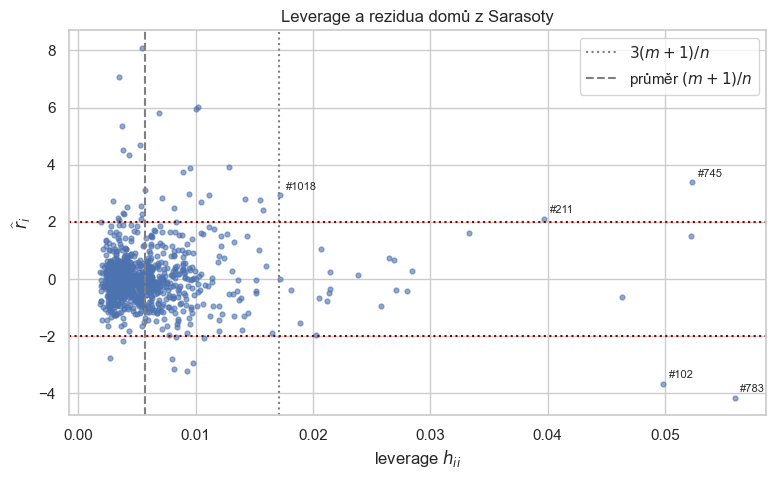

,price,living_area,bathrooms,bedrooms,age,h_ii,r_i
783,88092.0,3944,1.0,4,185,0.0559,-4.1623
745,599701.0,5114,4.5,5,131,0.0523,3.3757
102,59003.0,3285,2.0,5,233,0.0498,-3.6739
211,562546.0,5228,4.0,4,14,0.0397,2.1098
1018,479670.0,3956,2.5,4,15,0.0172,2.9329


In [48]:
# Krok 2: leverage, práh 3(m+1)/n a domy vysoké v h_ii i v r_i
h_mean, h_3 = p_h / n_h, 3 * p_h / n_h
high = pd.Series(h_h > h_3, index=houses.index)                  # logická maska domů nad prahem
print(f'průměrná leverage (m+1)/n = {h_mean:.4f},  práh 3(m+1)/n = {h_3:.4f},  domů nad prahem: {high.sum()}')
print(f'z nich starších než 100 let: {(houses.loc[high, "age"] > 100).sum()}, starších než 130 let: {(houses.loc[high, "age"] > 130).sum()},'
      f' větších než 3500 ft²: {(houses.loc[high, "living_area"] > 3500).sum()}')
display(scales_h.groupby(high)[['living_area', 'bathrooms', 'bedrooms', 'age']].median()
        .rename(index={False: 'h_ii <= práh', True: 'h_ii > práh'}).assign(počet=high.groupby(high).size().to_numpy()))

both = high & (np.abs(r_h) > 2)                                   # vysoká leverage i velké reziduum
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(h_h, r_h, s=12, alpha=0.6)
ax.axvline(h_3, color='gray', ls=':', label='$3(m+1)/n$')
ax.axvline(h_mean, color='gray', ls='--', label='průměr $(m+1)/n$')
for b in (-2, 2):                                                 # r_i mají přibližně rozdělení N(0,1), takže asi 95 % hodnot leží mezi -2 a 2
    ax.axhline(b, color='darkred', ls=':')
for i in np.flatnonzero(both):
    ax.annotate(f'#{i}', (h_h[i], r_h[i]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('leverage $h_{ii}$'); ax.set_ylabel('$\\widehat{r}_i$'); ax.legend()
ax.set_title('Leverage a rezidua domů z Sarasoty')
plt.show()
display(scales_h.loc[both, ['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'h_ii', 'r_i']].sort_values('h_ii', ascending=False))

### Závěr ke kroku 2
- Práh $3(m+1)/n = 0{,}0171$ překračuje **25 domů**. 
- Společné mají to, že jsou **starší než 100 let (18 domů, mediánně 161 let proti 17 u ostatních)** nebo **velmi velké (6 domů nad 3 500 ft²)**. Jsou to neobvyklé kombinace regresorů a $h_{ii}$ to ukáže ještě před použitím ceny.
- Na grafu $\widehat{r}_i$ proti $h_{ii}$ jsou vysoko v obou veličinách **pět domů**: č. 783 (3 944 ft², jedna koupelna, 185 let, $\widehat{r}_i = -4{,}2$), č. 102 (3 285 ft², 233 let, $-3{,}7$), č. 745 (5 114 ft², 4,5 koupelny, $+3{,}4$), č. 1018 ($+2{,}9$, těsně nad prahem) a č. 211 (5 228 ft², $+2{,}1$).
- Největší rezidua (č. 717, 719, 1038) mají naopak $h_{ii} \le 0{,}010$: velké reziduum samo o sobě neznamená vysokou leverage a naopak, vliv na přímku ukážou až míry vlivu.

### Krok 3. Grafy reziduí

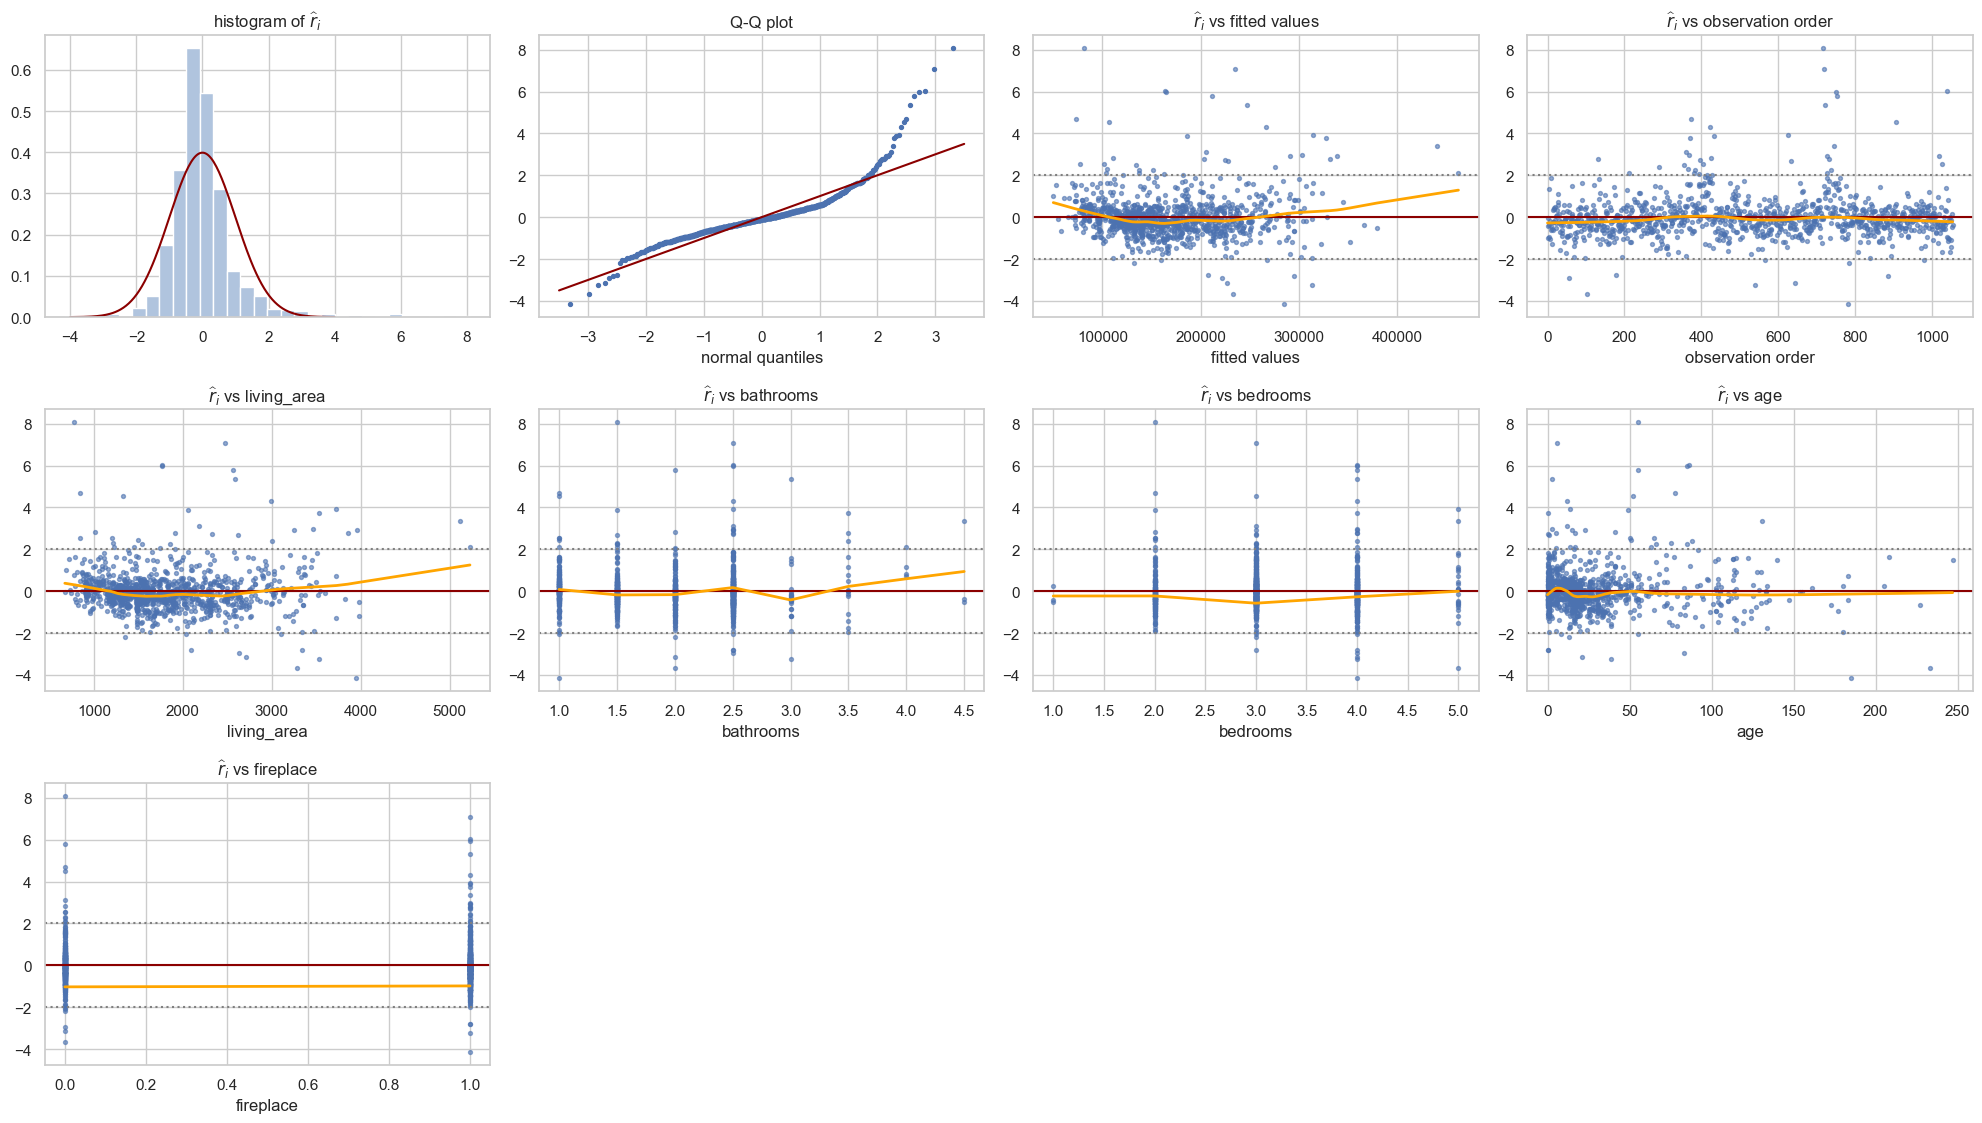

,SD r_i podle ŷ,průměr r_i podle ŷ,SD r_i podle living_area,průměr r_i podle living_area
pětina,,,,
1,0.9837,0.3039,0.9180,0.2489
2,0.6363,-0.1971,0.7788,-0.1234
3,0.9322,-0.1646,0.8759,-0.1409
4,0.8931,-0.0159,0.8748,-0.0807
5,1.3551,0.0738,1.3972,0.0972


In [49]:
# Krok 3: grafy reziduí proti ŷ, pořadí a každému regresoru
residual_plots(fit_h, houses, ['living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace'])

# číselná podpora: rozptyl a průměr r_i podle pětin ŷ a living_area
q_y = pd.qcut(fit_h.fittedvalues.to_numpy(), 5, labels=False) + 1
q_a = pd.qcut(houses['living_area'].to_numpy(), 5, labels=False) + 1
r_series = pd.Series(r_h)
display(pd.DataFrame({'SD r_i podle ŷ': r_series.groupby(q_y).std(), 'průměr r_i podle ŷ': r_series.groupby(q_y).mean(),
                      'SD r_i podle living_area': r_series.groupby(q_a).std(),
                      'průměr r_i podle living_area': r_series.groupby(q_a).mean()}).rename_axis('pětina'))

### Závěr ke kroku 3


| Graf | Co na něm vidíme | Který předpoklad to narušuje | Důsledek |
|---|---|---|---|
| $\widehat r_i$ vs $\widehat y$ (fitted values) | rezidua se s rostoucím $\widehat y$ rozptylují víc (nálevka) | konstantní rozptyl | $\widehat{\boldsymbol\beta}$ zůstává nestranný, ale směrodatné chyby, $t$-testy a intervaly spolehlivosti jsou špatně |
| histogram a Q-Q plot | pravý chvost je delší, body se na pravém konci odchylují od přímky | normalita chyb | při $n=1055$ jsou $t$ a $F$ přibližně v pořádku, ale predikční intervaly jsou nespolehlivé |
| $\widehat r_i$ vs pořadí | velká rezidua jsou v blocích řádků | nekorelované chyby | podezření na závislost mezi sousedními řádky, ověřuje se Durbin–Watsonem |
| $\widehat r_i$ vs `living_area` | nálevka jako u $\widehat y$ a lowess křivka mírně zakřivená (kladná rezidua u malých i velkých domů) | konstantní rozptyl a linearita | špatné směrodatné chyby a zkreslený odhad vlivu plochy |
| $\widehat r_i$ vs `bathrooms`, `bedrooms`, `age`, `fireplace` | lowess křivka je kolem nuly, u `age` se mírně ohýbá | linearita (u `age` slabě) | u těchto regresorů zásadní problém nevidíme |

**Shrnutí:** hlavní problém je nekonstantní rozptyl, dále šikmost reziduí doprava a mírné zakřivení vůči `living_area`. Odhady $\widehat{\boldsymbol\beta}$ zůstávají nestranné, ale inference (směrodatné chyby, testy, intervaly) je nespolehlivá.

### Krok 4. Grafy parciálních reziduí pro `age` a `living_area`

age: sklon přímky přes počátek = -141.1062, beta_j = -141.1062
living_area: sklon přímky přes počátek = 74.8408, beta_j = 74.8408


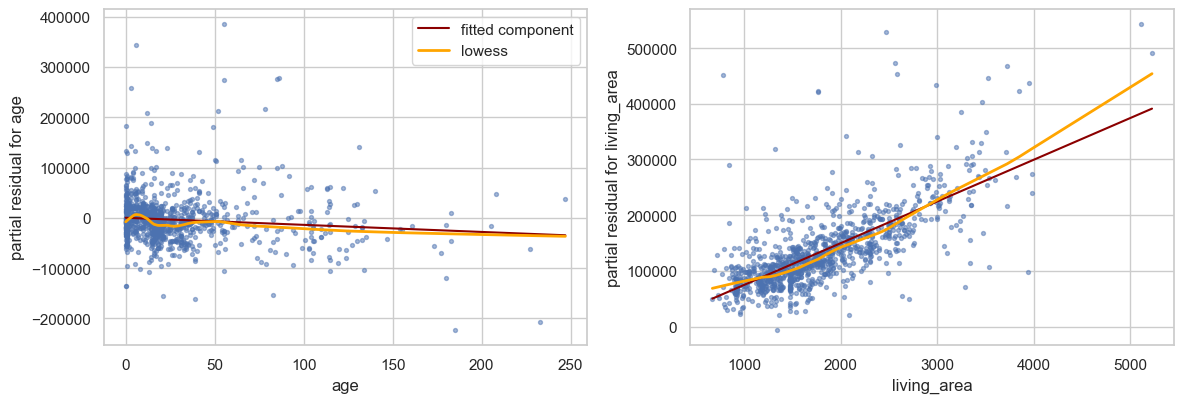

,R^2,s_n,koeficient u age,t přidaného členu
lineární,0.6032,48659.9731,-141.1062,NaN
+ age^2,0.6047,48595.3754,79.9812,-1.9470
"+ max(age - 100, 0)",0.6061,48510.1931,8.3558,-2.7364
+ living_area^2,0.6177,47785.8445,-168.2407,6.3031


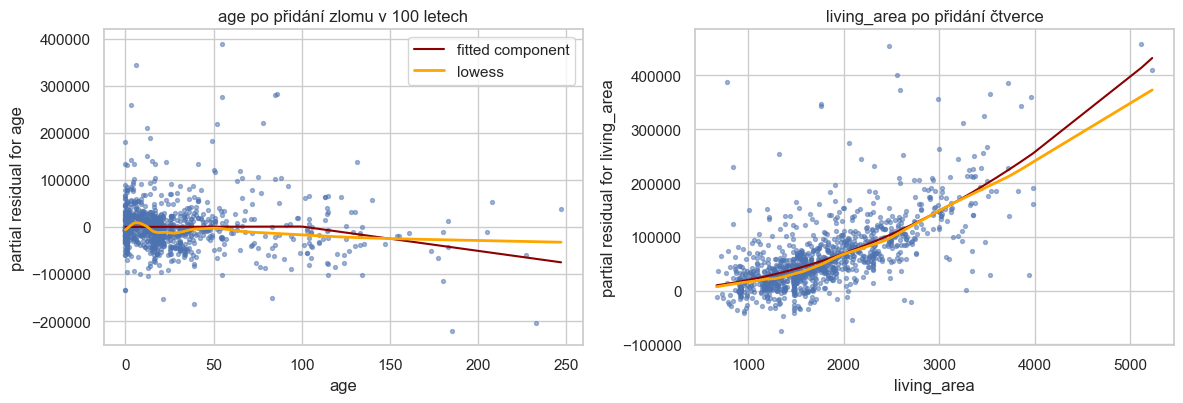

In [50]:
# Krok 4: grafy parciálních reziduí pro age a living_area
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, v in zip(axes, ['age', 'living_area']):
    pres = partial_residual_plot(fit_h, houses, v, ax)
    x = houses[v].to_numpy(dtype=float)
    print(f'{v}: sklon přímky přes počátek = {x @ pres / (x @ x):.4f}, beta_j = {fit_h.params[v]:.4f}')
axes[0].legend()
plt.tight_layout()
plt.show()

# jednoduché alternativy: age^2, zlomená přímka s zlomem v 100 letech, living_area^2
houses['age_over_100'] = np.maximum(houses['age'] - 100, 0)       # nula do 100 let, potom počet let nad 100
base = 'price ~ living_area + bathrooms + bedrooms + age + fireplace'
cands_h = {'lineární': base,
           '+ age^2': base + ' + I(age**2)',
           '+ max(age - 100, 0)': base + ' + age_over_100',
           '+ living_area^2': base + ' + I(living_area**2)'}
added = {'lineární': None, '+ age^2': 'I(age ** 2)', '+ max(age - 100, 0)': 'age_over_100', '+ living_area^2': 'I(living_area ** 2)'}
fits_h = {k_: smf.ols(f, data=houses).fit() for k_, f in cands_h.items()}
display(pd.DataFrame({k_: {'R^2': f.rsquared, 's_n': np.sqrt(f.scale), 'koeficient u age': f.params['age'],
                           't přidaného členu': f.tvalues[added[k_]] if added[k_] else np.nan}   
                      for k_, f in fits_h.items()}).T)   # H0: beta_nový člen = 0 (člen nic nepřináší); t = beta_hat / SE(beta_hat) ~ t(n-m-1) = t(1048), prakticky N(0,1)
# p < 0.05 (zhruba |t| > 2) -> H0 zamítáme, člen je významný

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
partial_residual_plot(fits_h['+ max(age - 100, 0)'], houses, 'age', axes[0], extra={'age_over_100': lambda x: np.maximum(x - 100, 0)})
partial_residual_plot(fits_h['+ living_area^2'], houses, 'living_area', axes[1], extra={'I(living_area ** 2)': lambda x: x ** 2})
axes[0].set_title('age po přidání zlomu v 100 letech'); axes[1].set_title('living_area po přidání čtverce')
axes[0].legend()
plt.tight_layout()
plt.show()


### Závěr ke kroku 4

**1. Grafy jsou správně sestrojené.** Sklon přímky přes počátek, vedené parciálními rezidui, vychází přesně $\widehat\beta_j$. Je to proto, že $\mathbf x_j^T\widehat{\mathbf e}=0$ (rezidua jsou kolmá na každý sloupec $\mathbf X$), takže součet $e_i+\widehat\beta_j x_{ij}$ má s $x_j$ stejnou lineární část jako model.

**2. Co ukazují grafy před úpravou (lineární model).**
- U `age` je lowess do asi 100 let prakticky vodorovný a teprve u starších domů klesá, strměji než přímka. Lineární sklon $-141$ USD za rok je tedy z velké části způsoben 71 domy staršími než 100 let. To souhlasí s HW04, úkol 06: po vyřazení domů nad 150 let klesl sklon na $-57$ a přestal být významný.
- U `living_area` leží lowess nad přímkou u domů nad asi 3 000 ft², tedy cena za ft² roste s velikostí domu (konvexní závislost).

**3. Zlepšilo se to? Srovnání modelů:**

| Model | $R^2$ | $s_n$ (USD) | $t$ přidaného členu | Zlepšení |
|---|---|---|---|---|
| lineární (výchozí) | 0,6032 | 48 660 | | |
| `+ age^2` | 0,6047 | 48 595 | $-1{,}95$ ($p=0{,}052$) | hraniční, nevýznamné na 5 % |
| `+ max(age - 100, 0)` | 0,6061 | 48 510 | $-2{,}74$ ($p=0{,}006$) | významné, ale malé |
| `+ living_area^2` | 0,6177 | 47 786 | $6{,}30$ | významné a největší |

- $R^2$ se přidáním libovolného sloupce **vždy** trochu zvýší, takže samotný růst $R^2$ nic neříká. Rozhodující je $t$-test přidaného členu a pokles $s_n$.
- **Věk:** zlom v 100 letech dává sklon asi $+8$ USD/rok do 100 let (prakticky nula) a asi $-518$ USD/rok nad 100 let (člen $-526$). Člen je významný, ale zlepšení je malé ($R^2$ vzroste jen o 0,003, $s_n$ klesne o asi 150 USD z 48 660). Čtverec věku je slabší, protože parabola klesá pozvolna už od mladých domů, zatímco data jsou do 100 let vodorovná a klesají až potom. Zlom v 100 letech jsme zvolili podle grafu, není to odhadnutý parametr, a výsledek závisí na malém počtu starých domů.
- **Plocha:** čtverec plochy zlepšuje model podstatně víc ($t=6{,}30$, $s_n$ klesne o asi 870 USD), protože zakřivení je u ceny za velikost domu skutečné a týká se velké části dat.

**4. Co se nezlepšilo.** Přidané členy upravují **střední hodnotu** (tvar závislosti), ale nic nedělají s **nekonstantním rozptylem** z kroku 3: nálevka v reziduích zůstává. Proto mají i po úpravě stále nespolehlivé směrodatné chyby a intervaly. K tomu je potřeba transformace nebo vážené nejmenší čtverce.


### Krok 5. Added variable plot pro `bedrooms`

sklon prosté regrese = 48383,  sklon AV přímky = -6583,  beta_bedrooms z modelu = -6583
max |rezidua AV přímky - rezidua modelu| = 1.4e-08
sd(bedrooms) = 0.740,  sd(bedrooms | ostatní) = 0.545,  poměr = 0.737
R^2 pomocné regrese = 0.457,  sqrt(1 - R^2) = 0.737,  VIF = 1.84


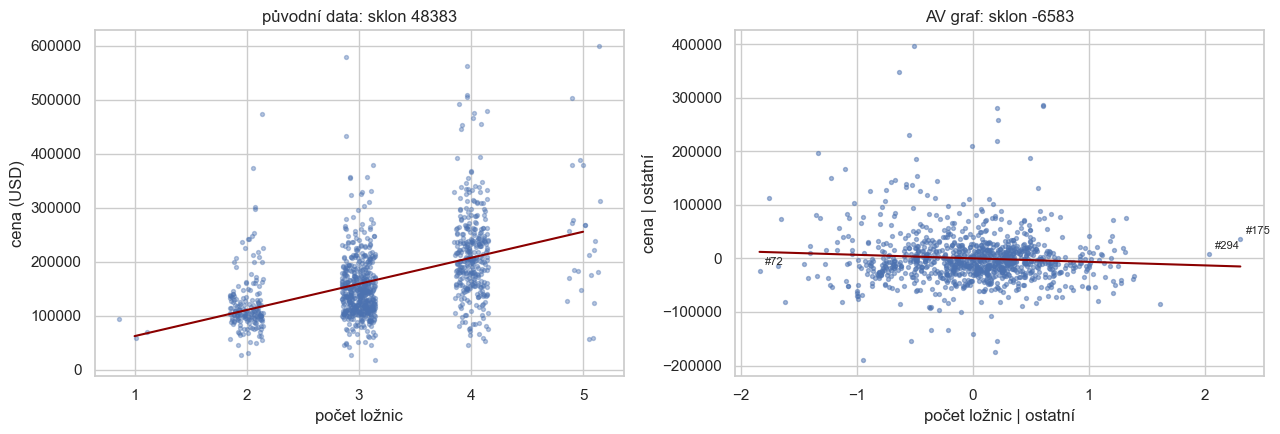

,price,living_area,bathrooms,bedrooms,age,x_res,e_y
175,123834.0,1092,1.0,5,72,2.3050,35749.2809
294,146611.0,1580,1.5,5,26,2.0345,7821.2925
72,224818.0,2738,2.5,2,12,-1.8385,-23700.3812
211,562546.0,5228,4.0,4,14,-1.7593,112183.0076
444,57678.0,924,1.0,1,104,-1.6752,-13448.1309


In [53]:
# Krok 5: added variable plot pro bedrooms a paradox z HW04, Úkol 04
simple_bed = smf.ols('price ~ bedrooms', data=houses).fit()
e_y, x_r = added_variable(fit_h, 'bedrooms')                       # (I - H_(-j)) y  a  (I - H_(-j)) x_j  (FWL)
slope_av = x_r @ e_y / (x_r @ x_r)
x_bed = houses['bedrooms'].to_numpy(dtype=float)
r2_bed = 1 - np.sum(x_r ** 2) / np.sum((x_bed - x_bed.mean()) ** 2)    # R^2 pomocné regrese bedrooms ~ ostatní
print(f'sklon prosté regrese = {simple_bed.params["bedrooms"]:.0f},  sklon AV přímky = {slope_av:.0f},  beta_bedrooms z modelu = {fit_h.params["bedrooms"]:.0f}')
print(f'max |rezidua AV přímky - rezidua modelu| = {np.abs(e_y - slope_av * x_r - e_h).max():.1e}')
print(f'sd(bedrooms) = {x_bed.std():.3f},  sd(bedrooms | ostatní) = {x_r.std():.3f},  poměr = {x_r.std() / x_bed.std():.3f}')
print(f'R^2 pomocné regrese = {r2_bed:.3f},  sqrt(1 - R^2) = {np.sqrt(1 - r2_bed):.3f},  VIF = {1 / (1 - r2_bed):.2f}')

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(x_bed + rng.uniform(-0.15, 0.15, n_h), y_h, s=8, alpha=0.4)           # lehký jitter, ložnic je jen 1 až 5
g = np.array([1, 5])
axes[0].plot(g, simple_bed.params['Intercept'] + simple_bed.params['bedrooms'] * g, color='darkred')
axes[0].set_xlabel('počet ložnic'); axes[0].set_ylabel('cena (USD)'); axes[0].set_title(f'původní data: sklon {simple_bed.params["bedrooms"]:.0f}')
axes[1].scatter(x_r, e_y, s=8, alpha=0.5)
g = np.linspace(x_r.min(), x_r.max(), 2)
axes[1].plot(g, slope_av * g, color='darkred')
for i in np.argsort(-np.abs(x_r))[:3]:
    axes[1].annotate(f'#{i}', (x_r[i], e_y[i]), fontsize=8, xytext=(4, 4), textcoords='offset points')
axes[1].set_xlabel('počet ložnic | ostatní'); axes[1].set_ylabel('cena | ostatní'); axes[1].set_title(f'AV graf: sklon {slope_av:.0f}')
plt.tight_layout()
plt.show()
idx5 = np.argsort(-np.abs(x_r))[:5]
display(houses.loc[idx5, ['price', 'living_area', 'bathrooms', 'bedrooms', 'age']].assign(x_res=x_r[idx5], e_y=e_y[idx5]))

### Závěr ke kroku 5
- **Osy:** vodorovně je počet ložnic po odečtení lineárního vlivu konstanty, krbu, plochy, koupelen a věku, $\mathbf{x}_{j,res} = (\mathbf{I} - \mathbf{H}_{(-j)})\mathbf{x}_j$, svisle cena očištěná stejným způsobem, $(\mathbf{I} - \mathbf{H}_{(-j)})\mathbf{y}$. Je to týž FWL (Frisch–Waugh–Lovell) postup jako v HW04
- **Sklon** přímky přes počátek je přesně $\widehat{\beta}_{\text{bedrooms}} = -6\,583$ USD za ložnici a rezidua kolem přímky jsou přesně rezidua celého modelu. V původních datech je sklon prosté regrese $+48\,383$: **paradox z HW04** je v tom, že větší dům má víc ložnic a je dražší kvůli ploše, ale když plochu (a koupelny, věk, krb) vyloučíme, má dům s více ložnicemi cenu nižší.
- **Vodorovný rozptyl a přesnost odhadu:** Původní ložnice mají směrodatnou odchylku $\mathrm{sd}(\text{bedrooms}) = 0{,}740$, po očištění $\mathrm{sd}(\mathbf{x}_{j,res}) = 0{,}545$, takže zůstává jen 74 % původního rozptylu. Je to proto, že ostatní regresory (hlavně plocha) vysvětlí $R_j^2 = 0{,}457$ variability ložnic (HW04) a zbývá $\sqrt{1 - R_j^2} = 0{,}74$. Tomu odpovídá $\mathrm{VIF} = 1/(1 - R_j^2) = 1{,}84$: rozptyl odhadu $\widehat{\beta}_j$ je 1,84krát větší, než by byl u nekorelovaných regresorů, což je mírná hodnota.
- **Co nese odhad:** domy na koncích osy, tedy neobvyklý počet ložnic při dané ploše: č. 175 (5 ložnic na 1 092 ft²) a č. 294 (5 ložnic na 1 580 ft²) vpravo, č. 72 (2 ložnice na 2 738 ft²) a č. 211 (4 ložnice na 5 228 ft²) vlevo. Koeficient je tedy odhadnutý z relativně úzkého rozptylu a opírá se o několik takových domů.

### Závěr
Model vysvětluje asi 60 % variability ceny, ale je chybně specifikovaný: rozptyl reziduí roste s velikostí domu (Breusch–Pagan $p \approx 2{,}5\cdot10^{-9}$, $\mathrm{SD}\,\widehat{r}_i$ 0,64 až 1,36) a rezidua mají těžký pravý chvost (18 domů s $|\widehat{t}_i| > 3$ místo asi 3), takže směrodatné chyby, testy a predikční intervaly jsou nespolehlivé. Efekt plochy je konvexní ($\mathrm{living\_area}^2$: $R^2$ z 0,603 na 0,618) a efekt věku lineární není: sklon $-141$ USD za rok vzniká z 71 domů starších než 100 let, zatímco do 100 let je sklon asi nulový. Odhady ovlivňuje 25 domů s vysokou leverage (staré nebo velmi velké) a několik domů s extrémní cenou za ft², které naznačují chybějící proměnnou (poloha, pozemek) nebo chybu v datech (č. 717, č. 783). Šlo by přidat čtverec plochy a zlom ve věku, pro inferenci použít robustní chyby nebo vážené nejmenší čtverce a prověřit extrémní domy u zpracovatele dat.

## 7. What to remember
- $\widehat{e}_i/s_n$ only for a quick look with small $h_{ii}$; $\widehat{r}_i$ for plots; $\widehat{t}_i \sim t(n-m-2)$ for outliers. No refit needed: $\mathrm{SSE}_{(-i)} = \mathrm{SSE} - \widehat{e}_i^2/(1-h_{ii})$.
- Names of residuals differ between books and software; check the formula.
- $h_{ii} \in [1/n, 1]$, $\sum_i h_{ii} = m+1$, large if $h_{ii} > 3(m+1)/n$. Leverage is about $\mathbf{x}$, the residual about $y$: a point can have one without the other.
- $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$: residual plots cannot show a linear trend in $x_j$ or $\widehat{y}$, only curvature and changing spread.
- PRP $\widehat{\mathbf{e}} + \widehat{\beta}_j\mathbf{x}_j$ vs $\mathbf{x}_j$: the shape of the effect. AV plot $\widehat{\mathbf{e}}_{(-j)}$ vs $\mathbf{x}_{j,res}$: slope $\widehat{\beta}_j$, residuals of the full model, the information about $\beta_j$ (FWL).
- With correlated regressors the plots borrow each other's patterns: refit and look again.
- Next: Exercise 08 asks which points change the fit (PRESS, DFBETAS, Cook's distance, DFFITS) and what to do with them (robust regression).